In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
from scipy.special import expit

# **Definición del Problema**

Queremos resolver la EDO No-Lineal para $N$ regiones acopladas por permitividad:



$$
\dot x_i = 1 - x_i^3 - 2x_i^2 - z_i + I_1,\qquad \\
\dot z_i = \frac{1}{\tau_0}\Big(h(x_i) - z_i - K\sum_{j=1}^{N}\,(x_j - x_i)\Big)
$$
con
$$
h(x_i) = x_{0,i} + \frac{3}{1+\exp\!\big(-(x_i+0.5)/0.1\big)},\qquad \tau_0 = 2857,\quad I_1 = 3.1
$$

# **Parámetros Globales**

In [ ]:
tau0 = 2857
I1 = 3.1

# **Resolveremos primero para $N=1$. De esta manera tenemos la siguiente ecuación:**



$$
\begin{aligned}
\dot{x}_1 &= -x_1^3 - 2x_1^2 + 1 - z + I_1 \\[6pt]
\dot{z} &= \frac{1}{\tau_0}\left(h(x_1) - z\right)
\end{aligned}
$$

El parámetro $x_0$ controla la excitabilidad de la región:
- Si $x_0 < 2.91$, el sistema presenta actividad ictal autónoma (epileptogénico).
- Si $x_0 > 2.91$, el sistema permanece en un equilibrio estable interictal (sano).

# **Definición de la Función Sigmoide**

In [ ]:
def h(x, x0_val):
    return x0_val + 3 * expit((x + 0.5) / 0.1)

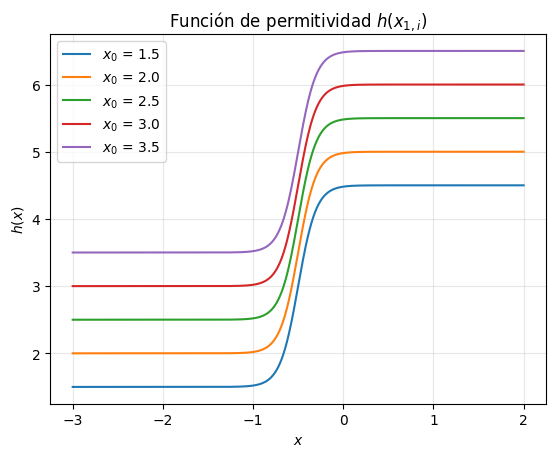

In [ ]:
x = np.linspace(-3, 2, 1000)
x0_lista = [1.5, 2.0, 2.5, 3.0, 3.5]

plt.figure()
for a in x0_lista:
    plt.plot(x, h(x, a), label=f'$x_0$ = {a}')
plt.xlabel("$x$"); plt.ylabel("$h(x)$")
plt.title("Función de permitividad $h(x_{1,i})$")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# **Para $N=1$ tenemos el Campo Vectorial:**

In [ ]:
def vector_field(x, z, x0_val):
    dx = -x**3 - 2*x**2 + 1 - z + I1
    dz = (h(x, x0_val) - z) / tau0
    return dx, dz

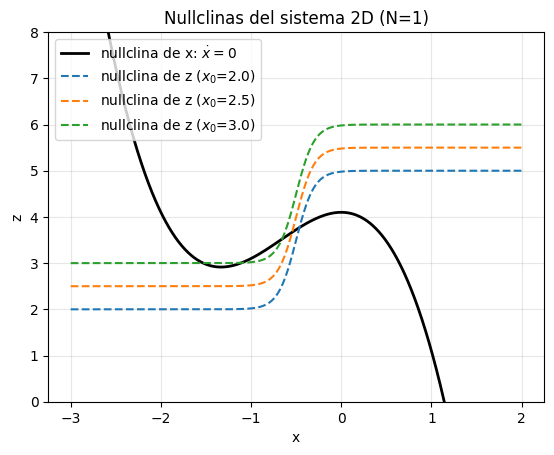

In [ ]:
x = np.linspace(-3, 2, 1000)
z_x = -x**3 - 2*x**2 + 1 + I1

plt.figure()
plt.plot(x, z_x, 'k', lw=2, label='nullclina de x: $\\dot x=0$')
for a in [2.0, 2.5, 3.0]:
    plt.plot(x, h(x, a), '--', label=f'nullclina de z ($x_0$={a})')
plt.ylim(0, 8)
plt.xlabel('x'); plt.ylabel('z')
plt.title('Nullclinas del sistema 2D (N=1)')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [ ]:
def f_fijo(x, x0):
    return -x**3 - 2*x**2 + 1 + I1 - h(x, x0)

def puntos_fijos(x0, xmin=-3, xmax=3, n=6001):
    xs = np.linspace(xmin, xmax, n)
    fs = f_fijo(xs, x0)
    idx = np.where(np.sign(fs[:-1])*np.sign(fs[1:]) < 0)[0]
    return [brentq(f_fijo, xs[i], xs[i+1], args=(x0,)) for i in idx]

def dh_dx(x):
    s = expit((x + 0.5)/0.1)
    return 3*s*(1 - s)/0.1

def jacobiano(x):
    return np.array([[-3*x**2 - 4*x, -1.0],
                     [dh_dx(x)/tau0, -1.0/tau0]])

for a in [2.0, 2.5, 2.8, 3.0, 3.5]:
    print(f'\n=== x0 = {a} ===')
    for xs_ in puntos_fijos(a):
        zs_ = h(xs_, a)
        lam = np.linalg.eigvals(jacobiano(xs_))
        est = 'ESTABLE' if np.all(lam.real < 0) else 'INESTABLE'
        print(f'  (x*, z*) = ({xs_:.4f}, {zs_:.4f})  '
              f'autovalores = {np.round(lam, 5)}  -> {est}')


=== x0 = 2.0 ===
  (x*, z*) = (-0.4636, 3.7697)  autovalores = [1.20757 0.00175]  -> INESTABLE

=== x0 = 2.5 ===
  (x*, z*) = (-0.5450, 3.6678)  autovalores = [1.28702 0.00159]  -> INESTABLE

=== x0 = 2.8 ===
  (x*, z*) = (-0.6024, 3.5929)  autovalores = [1.31939e+00 1.20000e-03]  -> INESTABLE

=== x0 = 3.0 ===
  (x*, z*) = (-1.5304, 3.0001)  autovalores = [-9.0455e-01 -3.5000e-04]  -> ESTABLE
  (x*, z*) = (-1.1052, 3.0070)  autovalores = [ 7.5641e-01 -3.2000e-04]  -> INESTABLE
  (x*, z*) = (-0.6558, 3.5219)  autovalores = [1.33184e+00 7.80000e-04]  -> INESTABLE

=== x0 = 3.5 ===
  (x*, z*) = (-1.8186, 3.5000)  autovalores = [-2.64739e+00 -3.50000e-04]  -> ESTABLE


# **Generador de Condiciones Iniciales Aleatorias**.

In [ ]:
rng = np.random.default_rng(42)

def cond_iniciales(N, rng=rng):
    x_ini = 4.0 * (rng.random(N) - 1)         # uniforme en [-2, 2]
    z_ini = 3.0 + 2.0 * (rng.random(N) - 0.5)    # uniforme en [2, 4]
    return x_ini, z_ini

# **Simulaciones de Series de Tiempo**.

In [ ]:
def simular(x0, T=30000, y0=None, dt=1.0):
    if y0 is None:                               # si no pasas y0, se sortea
        x_ini, z_ini = cond_iniciales(1)
        y0 = (x_ini[0], z_ini[0])
    sol = solve_ivp(lambda t, y: vector_field(y[0], y[1], x0),
                    (0, T), y0, method='LSODA',
                    t_eval=np.arange(0, T + dt, dt),
                    rtol=1e-8, atol=1e-10)
    return sol.t, sol.y[0], sol.y[1]

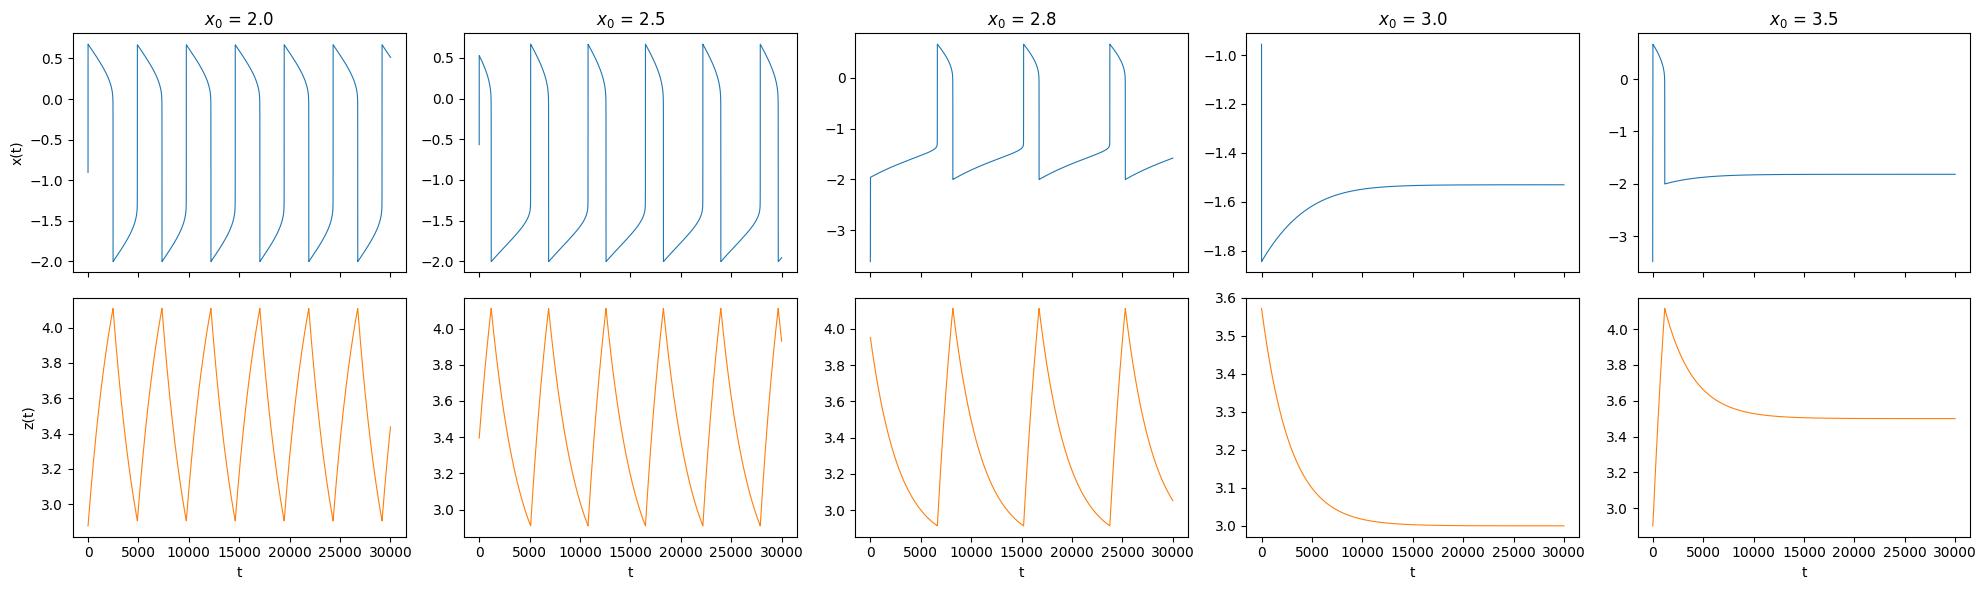

In [ ]:
x0_sim = [2.0, 2.5, 2.8, 3.0, 3.5]
resultados = {a: simular(a) for a in x0_sim}

fig, ax = plt.subplots(2, len(x0_sim), figsize=(20, 6), sharex=True)
for j, a in enumerate(x0_sim):
    t, xx, zz = resultados[a]
    ax[0, j].plot(t, xx, lw=0.8); ax[0, j].set_title(f'$x_0$ = {a}')
    ax[1, j].plot(t, zz, 'C1', lw=0.8); ax[1, j].set_xlabel('t')
ax[0, 0].set_ylabel('x(t)'); ax[1, 0].set_ylabel('z(t)')
plt.tight_layout()
plt.show()

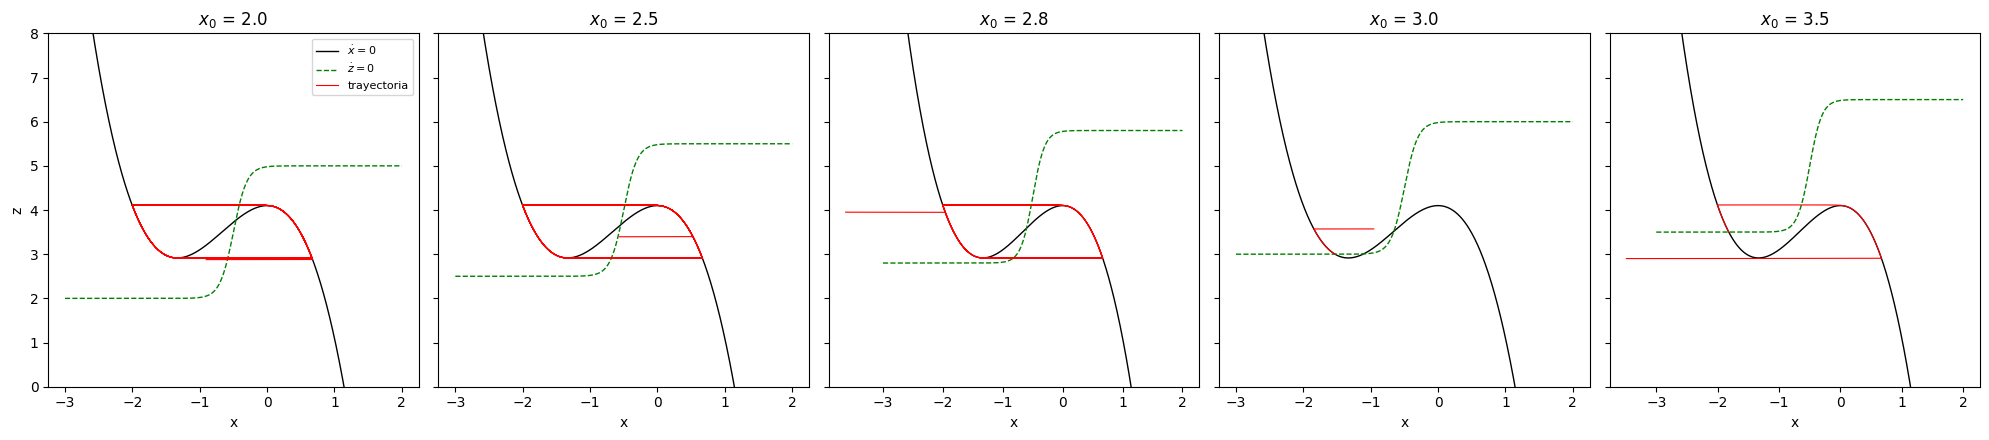

In [ ]:
xg = np.linspace(-3, 2, 1000)

fig, ax = plt.subplots(1, len(x0_sim), figsize=(20, 4.5), sharey=True)
for j, a in enumerate(x0_sim):
    t, xx, zz = resultados[a]
    ax[j].plot(xg, -xg**3 - 2*xg**2 + 1 + I1, 'k', lw=1, label='$\\dot x=0$')
    ax[j].plot(xg, h(xg, a), 'g--', lw=1, label='$\\dot z=0$')
    ax[j].plot(xx, zz, 'r', lw=0.8, label='trayectoria')
    ax[j].set_title(f'$x_0$ = {a}'); ax[j].set_xlabel('x')
    ax[j].set_ylim(0, 8)
ax[0].set_ylabel('z'); ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# **Serie de Tiempo para el punto crítico $x_0= 2.91$**.

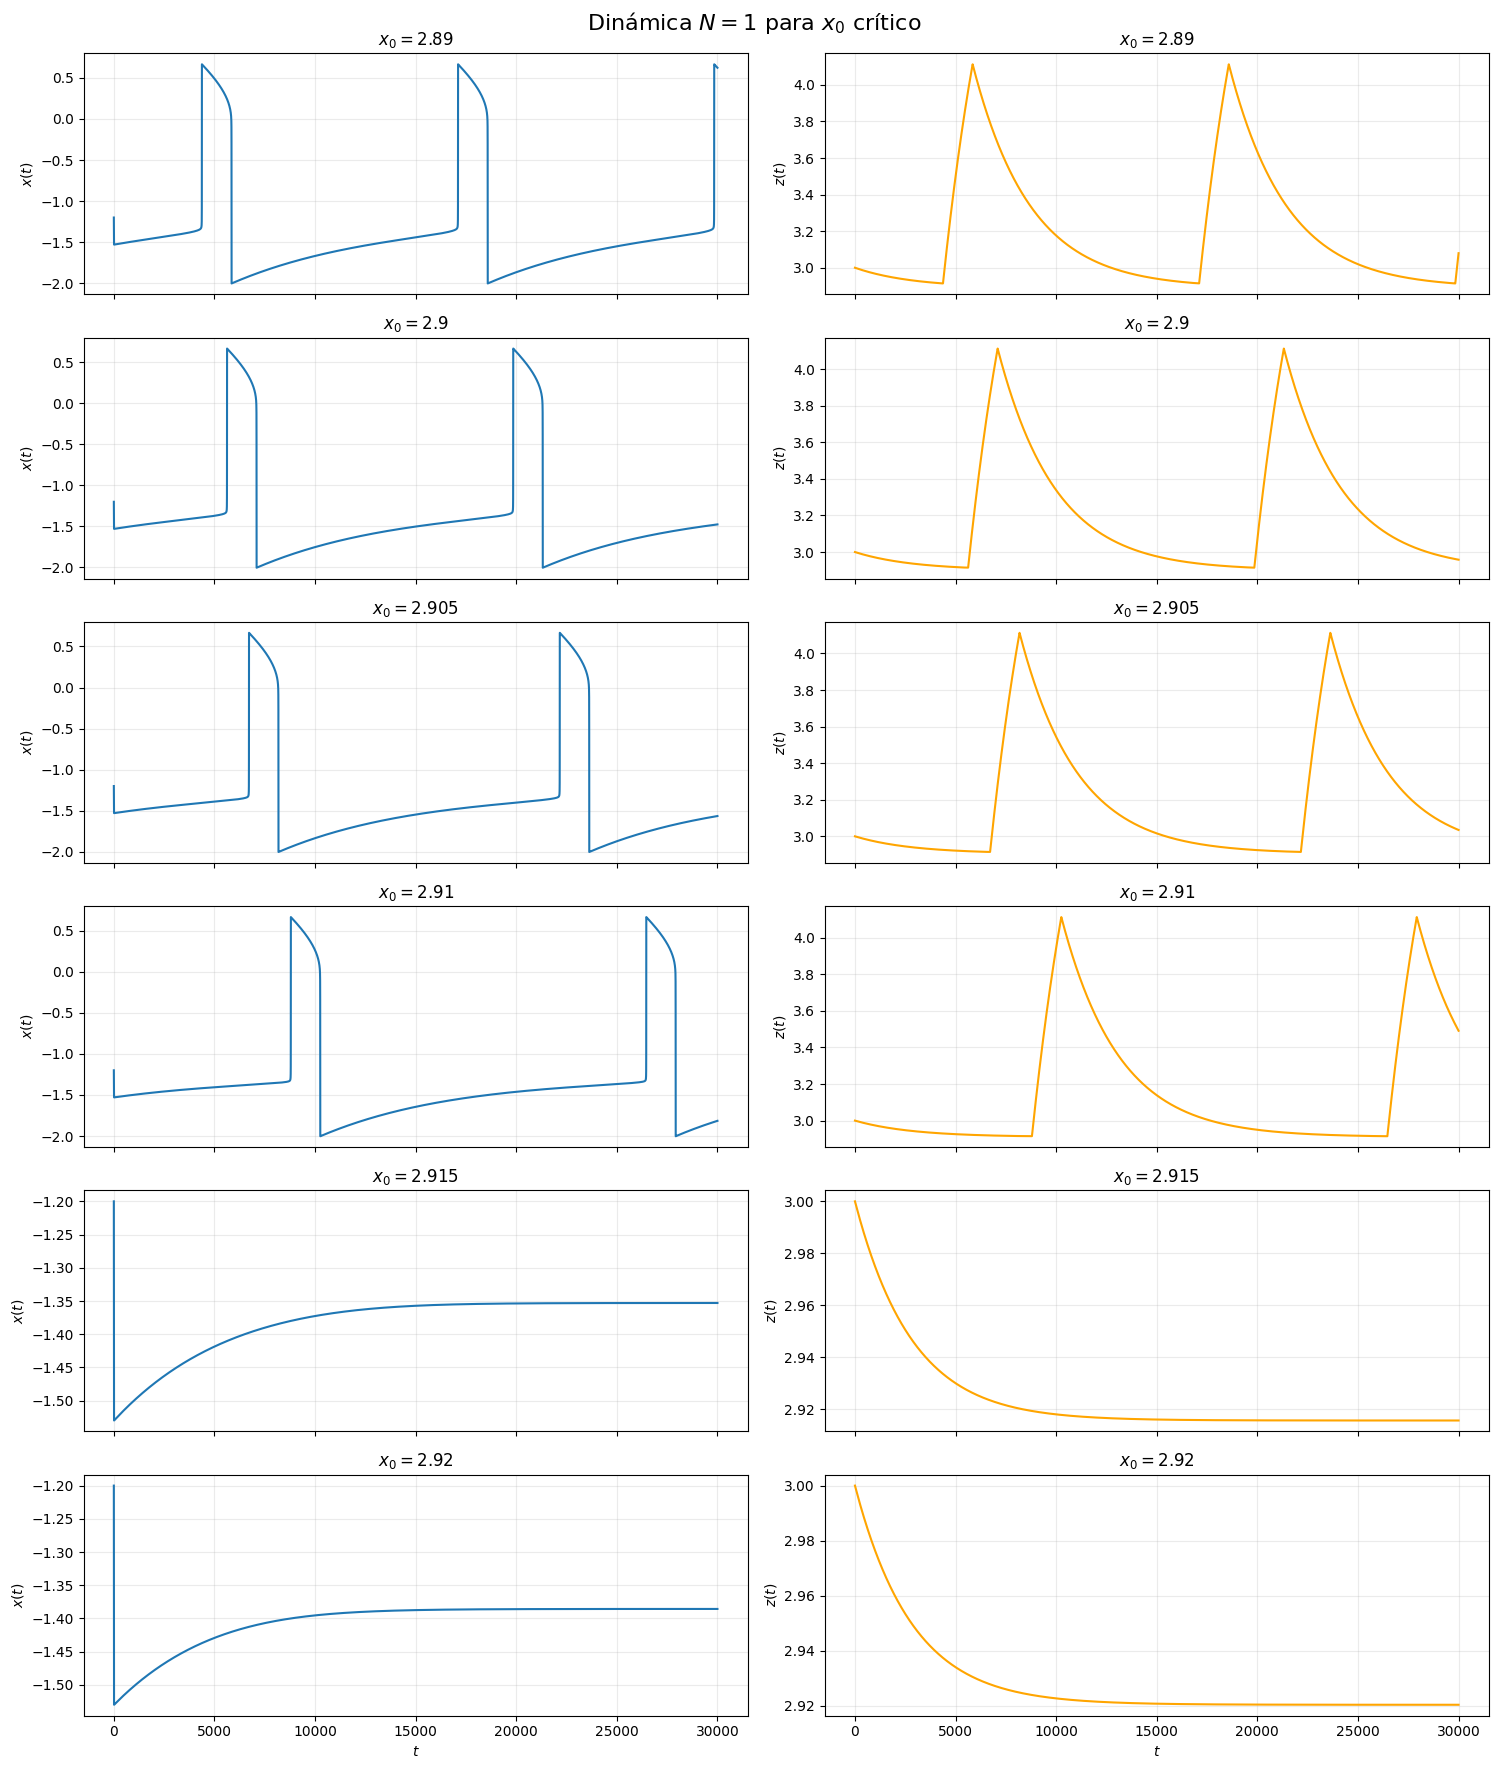

In [ ]:
x0_values = [2.89,2.90,2.905,2.91,2.915,2.92]
T = 30000
dt = 1.0

fig, axes = plt.subplots(
    len(x0_values), 2,
    figsize=(15, 3 * len(x0_values)),
    sharex=True
)

for i, x0_val in enumerate(x0_values):
    t, x, z = simular(
        x0=x0_val,
        T=T,
        y0=(-1.2, 3.0),
        dt=dt
    )
    axes[i, 0].plot(t, x)
    axes[i, 0].set_ylabel(r"$x(t)$")
    axes[i, 0].set_title(rf"$x_0={x0_val}$")
    axes[i, 0].grid(alpha=0.25)
    axes[i, 1].plot(t, z, color="orange")
    axes[i, 1].set_ylabel(r"$z(t)$")
    axes[i, 1].set_title(rf"$x_0={x0_val}$")
    axes[i, 1].grid(alpha=0.25)
axes[-1, 0].set_xlabel(r"$t$")
axes[-1, 1].set_xlabel(r"$t$")

fig.suptitle(
    r"Dinámica $N=1$ para $x_0$ crítico",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
from scipy.signal import find_peaks

def analizar(x0_val, T=60000, dt=0.5, frac_trans=0.5, prom=0.5):
    t, x, z = simular(x0_val, T=T, dt=dt)
    m = t >= frac_trans * T
    tt, xx = t[m], x[m]

    pk, _ = find_peaks(xx, prominence=prom)
    t_pk, x_pk = tt[pk], xx[pk]

    if len(pk) >= 2:
        periodo = np.mean(np.diff(t_pk))
        frec_1T = 1.0 / periodo
    else:
        periodo, frec_1T = np.nan, 0.0

    frec_conteo = len(pk) / (tt[-1] - tt[0])
    amplitud = xx.max() - xx.min()

    return dict(x0=x0_val, periodo=periodo, frec_1T=frec_1T,
                frec_conteo=frec_conteo, amplitud=amplitud,
                t_pk=t_pk, x_pk=x_pk, x_min=xx.min(), x_max=xx.max())

x0_grid = np.unique(np.concatenate([
    np.linspace(2.00, 2.85, 35),
    np.linspace(2.85, 2.95, 41),
    np.linspace(2.95, 3.30, 15)
]))

barrido = []
for a in x0_grid:
    barrido.append(analizar(a))
    print(f"x0 = {a:.3f} | spikes = {len(barrido[-1]['x_pk'])} | "
          f"T = {barrido[-1]['periodo']:.1f}")

x0s = np.array([r['x0'] for r in barrido])

x0 = 2.000 | spikes = 6 | T = 4853.9
x0 = 2.025 | spikes = 6 | T = 4854.6
x0 = 2.050 | spikes = 5 | T = 4858.8
x0 = 2.075 | spikes = 6 | T = 4866.4
x0 = 2.100 | spikes = 5 | T = 4877.9
x0 = 2.125 | spikes = 5 | T = 4893.0
x0 = 2.150 | spikes = 6 | T = 4911.8
x0 = 2.175 | spikes = 6 | T = 4934.5
x0 = 2.200 | spikes = 6 | T = 4961.3
x0 = 2.225 | spikes = 6 | T = 4992.2
x0 = 2.250 | spikes = 6 | T = 5027.6
x0 = 2.275 | spikes = 6 | T = 5067.5
x0 = 2.300 | spikes = 6 | T = 5112.2
x0 = 2.325 | spikes = 6 | T = 5162.0
x0 = 2.350 | spikes = 5 | T = 5217.5
x0 = 2.375 | spikes = 5 | T = 5278.8
x0 = 2.400 | spikes = 5 | T = 5346.5
x0 = 2.425 | spikes = 5 | T = 5421.1
x0 = 2.450 | spikes = 5 | T = 5503.4
x0 = 2.475 | spikes = 5 | T = 5594.0
x0 = 2.500 | spikes = 5 | T = 5694.0
x0 = 2.525 | spikes = 5 | T = 5804.4
x0 = 2.550 | spikes = 5 | T = 5926.6
x0 = 2.575 | spikes = 5 | T = 6062.1
x0 = 2.600 | spikes = 5 | T = 6213.1
x0 = 2.625 | spikes = 5 | T = 6382.0
x0 = 2.650 | spikes = 4 | T = 6572.3
x

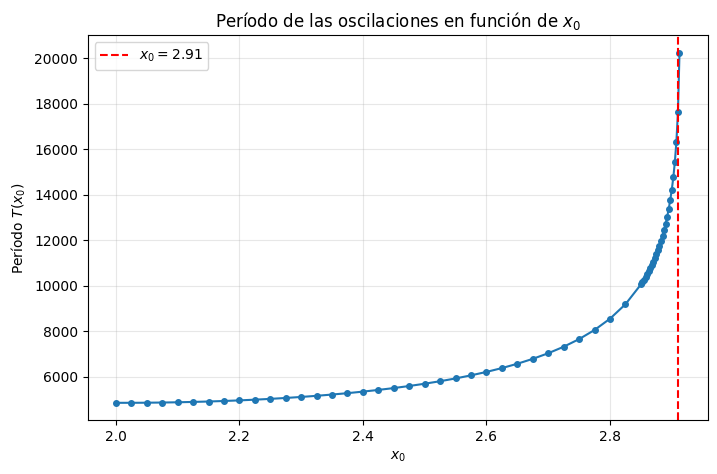

In [ ]:
periodos = np.array([r['periodo'] for r in barrido])

plt.figure(figsize=(8, 5))
plt.plot(x0s, periodos, 'o-', ms=4)
plt.axvline(2.91, color='r', ls='--', label='$x_0 = 2.91$')
plt.xlabel('$x_0$'); plt.ylabel('Período $T(x_0)$')
plt.title('Período de las oscilaciones en función de $x_0$')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

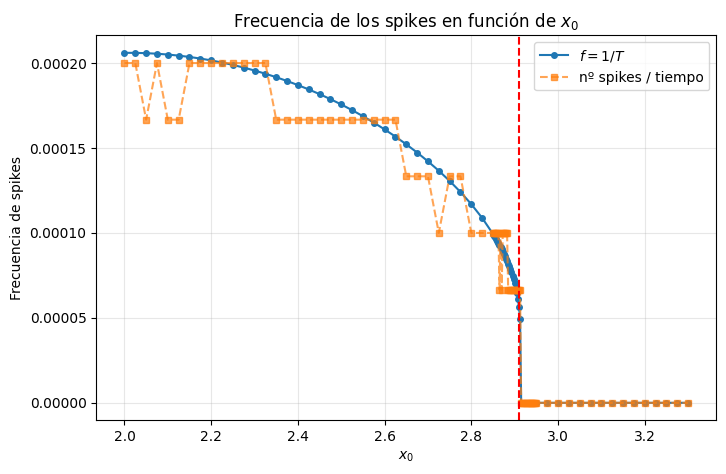

In [ ]:
f_1T = np.array([r['frec_1T'] for r in barrido])
f_cnt = np.array([r['frec_conteo'] for r in barrido])

plt.figure(figsize=(8, 5))
plt.plot(x0s, f_1T, 'o-', ms=4, label='$f = 1/T$')
plt.plot(x0s, f_cnt, 's--', ms=4, alpha=0.7, label='nº spikes / tiempo')
plt.axvline(2.91, color='r', ls='--')
plt.xlabel('$x_0$'); plt.ylabel('Frecuencia de spikes')
plt.title('Frecuencia de los spikes en función de $x_0$')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

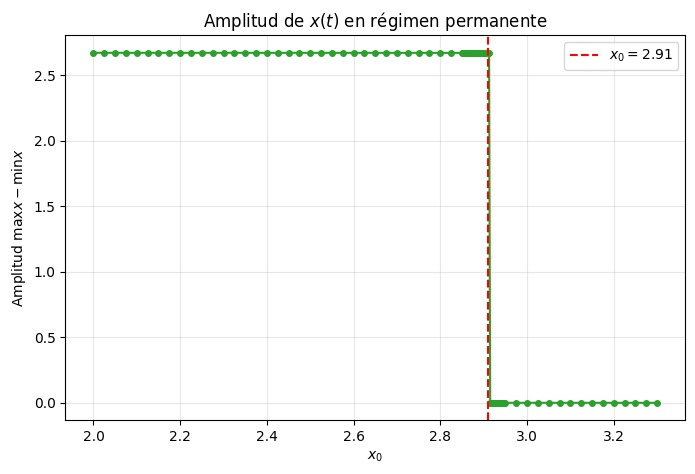

In [ ]:
amps = np.array([r['amplitud'] for r in barrido])

plt.figure(figsize=(8, 5))
plt.plot(x0s, amps, 'o-', ms=4, color='C2')
plt.axvline(2.91, color='r', ls='--', label='$x_0 = 2.91$')
plt.xlabel('$x_0$'); plt.ylabel(r'Amplitud $\max x - \min x$')
plt.title('Amplitud de $x(t)$ en régimen permanente')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

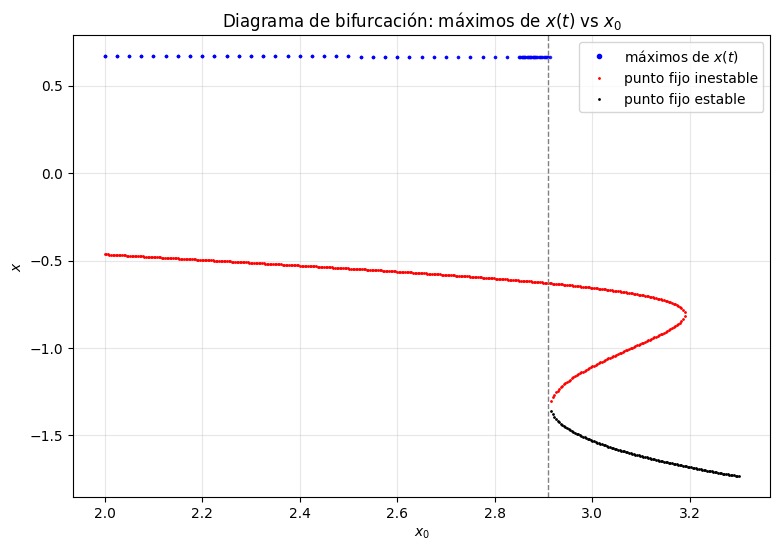

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))

for r in barrido:
    if len(r['x_pk']) > 0:
        ax.plot(np.full(len(r['x_pk']), r['x0']), r['x_pk'],
                'b.', ms=3, alpha=0.5)
ax.plot([], [], 'b.', label='máximos de $x(t)$')

x0_fino = np.linspace(x0s.min(), x0s.max(), 400)
est_lab, inest_lab = False, False
for a in x0_fino:
    for xs_ in puntos_fijos(a):
        lam = np.linalg.eigvals(jacobiano(xs_))
        if np.all(lam.real < 0):
            ax.plot(a, xs_, 'k.', ms=2,
                    label='punto fijo estable' if not est_lab else None)
            est_lab = True
        else:
            ax.plot(a, xs_, 'r.', ms=2,
                    label='punto fijo inestable' if not inest_lab else None)
            inest_lab = True

ax.axvline(2.91, color='gray', ls='--', lw=1)
ax.set_xlabel('$x_0$'); ax.set_ylabel('$x$')
ax.set_title('Diagrama de bifurcación: máximos de $x(t)$ vs $x_0$')
ax.legend(loc='best'); ax.grid(alpha=0.3)
plt.show()

## Para dos regiones acopladas $N=2$, el término de acoplamiento actúa sobre las variables de permitividad $z_1$ y $z_2$. El sistema reducido en 4D queda:

> Añadir blockquote



$$
\begin{aligned}
\dot{x}_{1,1} &= -x_{1,1}^3 - 2x_{1,1}^2 + 1 - z_1 + I_1 \\[6pt]
\dot{x}_{1,2} &= -x_{1,2}^3 - 2x_{1,2}^2 + 1 - z_2 + I_1 \\[6pt]
\dot{z}_1 &= \frac{1}{\tau_0}\Big(h(x_{1,1}) - z_1 - K(x_{1,2} - x_{1,1})\Big) \\[6pt]
\dot{z}_2 &= \frac{1}{\tau_0}\Big(h(x_{1,2}) - z_2 - K(x_{1,1} - x_{1,2})\Big)
\end{aligned}
$$

# **Definición del Campo Vectorial**

In [ ]:
def rhs_N2(t, y, x0_1, x0_2, K):
    x1, x2, z1, z2 = y
    dx1 = -x1**3 - 2*x1**2 + 1 - z1 + I1
    dx2 = -x2**3 - 2*x2**2 + 1 - z2 + I1
    dz1 = (h(x1, x0_1) - z1 - K*(x2 - x1)) / tau0
    dz2 = (h(x2, x0_2) - z2 - K*(x1 - x2)) / tau0
    return [dx1, dx2, dz1, dz2]


In [ ]:
def simular_N2(x0_1, x0_2, K, T=30000, y0=None, dt=1.0):
    if y0 is None:                      # reposo de cada región: x en rama baja, z = x0_i
        y0 = (-1.5, -1.5, x0_1, x0_2)
    sol = solve_ivp(lambda t, y: rhs_N2(t, y, x0_1, x0_2, K),
                    (0, T), y0, method='LSODA',
                    t_eval=np.arange(0, T + dt, dt),
                    rtol=1e-8, atol=1e-10)
    x1, x2, z1, z2 = sol.y
    return sol.t, x1, x2, z1, z2

In [ ]:
def f_cubica(x):
    return -x**3 - 2*x**2 + 1 + I1

def jacobiano_N2(x1, x2, K):
    return np.array([
        [-3*x1**2 - 4*x1, 0.0,              -1.0,      0.0],
        [0.0,             -3*x2**2 - 4*x2,   0.0,     -1.0],
        [(dh_dx(x1) + K)/tau0, -K/tau0,     -1.0/tau0, 0.0],
        [-K/tau0, (dh_dx(x2) + K)/tau0,      0.0,     -1.0/tau0]
    ])

def puntos_fijos_N2(x0, K, xmin=-3, xmax=3, n=6001):
    """Devuelve lista de (x1, x2, z1, z2). Requiere K != 0."""
    g = lambda x: f_cubica(x) - h(x, x0)

    def F(x1):
        x2 = x1 - g(x1) / K
        return g(x2) + K * (x1 - x2)

    xs = np.linspace(xmin, xmax, n)
    Fs = F(xs)
    idx = np.where(np.sign(Fs[:-1]) * np.sign(Fs[1:]) < 0)[0]
    sols = []
    for i in idx:
        x1 = brentq(F, xs[i], xs[i+1])
        x2 = x1 - g(x1) / K
        sols.append((x1, x2, f_cubica(x1), f_cubica(x2)))
    return sols

def reporte_puntos_fijos_N2(x0, K):
    print(f'\n=== x0 = {x0}, K = {K} ===')
    for (x1, x2, z1, z2) in puntos_fijos_N2(x0, K):
        lam = np.linalg.eigvals(jacobiano_N2(x1, x2, K))
        est = 'ESTABLE' if np.all(lam.real < 0) else 'INESTABLE'
        print(f'  (x1,x2,z1,z2) = ({x1:.4f}, {x2:.4f}, {z1:.4f}, {z2:.4f})  '
              f'max Re(λ) = {lam.real.max():.5f} -> {est}')

for K in [0.1, 0.5, 1.0]:
    for a in [2.5, 2.9, 3.5]:
        reporte_puntos_fijos_N2(a, K)


=== x0 = 2.5, K = 0.1 ===
  (x1,x2,z1,z2) = (-0.5450, -0.5450, 3.6678, 3.6678)  max Re(λ) = 1.28702 -> INESTABLE

=== x0 = 2.9, K = 0.1 ===
  (x1,x2,z1,z2) = (-0.6264, -0.6264, 3.5611, 3.5611)  max Re(λ) = 1.32710 -> INESTABLE

=== x0 = 3.5, K = 0.1 ===
  (x1,x2,z1,z2) = (-1.8186, -1.8186, 3.5000, 3.5000)  max Re(λ) = -0.00035 -> ESTABLE

=== x0 = 2.5, K = 0.5 ===
  (x1,x2,z1,z2) = (-0.5450, -0.5450, 3.6678, 3.6678)  max Re(λ) = 1.28702 -> INESTABLE

=== x0 = 2.9, K = 0.5 ===
  (x1,x2,z1,z2) = (-0.6264, -0.6264, 3.5611, 3.5611)  max Re(λ) = 1.32710 -> INESTABLE

=== x0 = 3.5, K = 0.5 ===
  (x1,x2,z1,z2) = (-1.8186, -1.8186, 3.5000, 3.5000)  max Re(λ) = -0.00035 -> ESTABLE

=== x0 = 2.5, K = 1.0 ===
  (x1,x2,z1,z2) = (-0.5450, -0.5450, 3.6678, 3.6678)  max Re(λ) = 1.28702 -> INESTABLE

=== x0 = 2.9, K = 1.0 ===
  (x1,x2,z1,z2) = (-0.6264, -0.6264, 3.5611, 3.5611)  max Re(λ) = 1.32710 -> INESTABLE

=== x0 = 3.5, K = 1.0 ===
  (x1,x2,z1,z2) = (-1.8186, -1.8186, 3.5000, 3.5000)  max Re(λ)

# **Series de Tiempo para N=2**.

In [ ]:
def series_tiempo_N2(K, x0_lista, T=30000, dt=1.0, y0=None):
    n = len(x0_lista)

    if y0 is None:
        x_ini, z_ini = cond_iniciales(2)
        y0 = (x_ini[0], x_ini[1], z_ini[0], z_ini[1])

    fig, axes = plt.subplots(n, 2, figsize=(16, 2.8 * n), sharex=True)

    for i, a in enumerate(x0_lista):
        t, x1, x2, z1, z2 = simular_N2(a, a, K, T=T, y0=y0, dt=dt)

        axes[i, 0].plot(t, x1, lw=0.8, label='$x_1$')
        axes[i, 0].plot(t, x2, lw=0.8, alpha=0.8, label='$x_2$')
        axes[i, 0].set_ylabel('x'); axes[i, 0].set_title(rf'$x_0={a}$')
        axes[i, 0].grid(alpha=0.25)

        axes[i, 1].plot(t, z1, 'C2', lw=0.8, label='$z_1$')
        axes[i, 1].plot(t, z2, 'C3', lw=0.8, alpha=0.8, label='$z_2$')
        axes[i, 1].set_ylabel('z'); axes[i, 1].set_title(rf'$x_0={a}$')
        axes[i, 1].grid(alpha=0.25)

        if i == 0:
            axes[i, 0].legend(loc='upper right'); axes[i, 1].legend(loc='upper right')

    axes[-1, 0].set_xlabel('t'); axes[-1, 1].set_xlabel('t')
    fig.suptitle(rf'Series de tiempo, $N=2$, $K={K}$', fontsize=16)
    plt.tight_layout()
    plt.show()

# **Observamos la Dinámica para varios $x_0$ y variables de Acoplamiento $K$**.

- $K=0.01$.

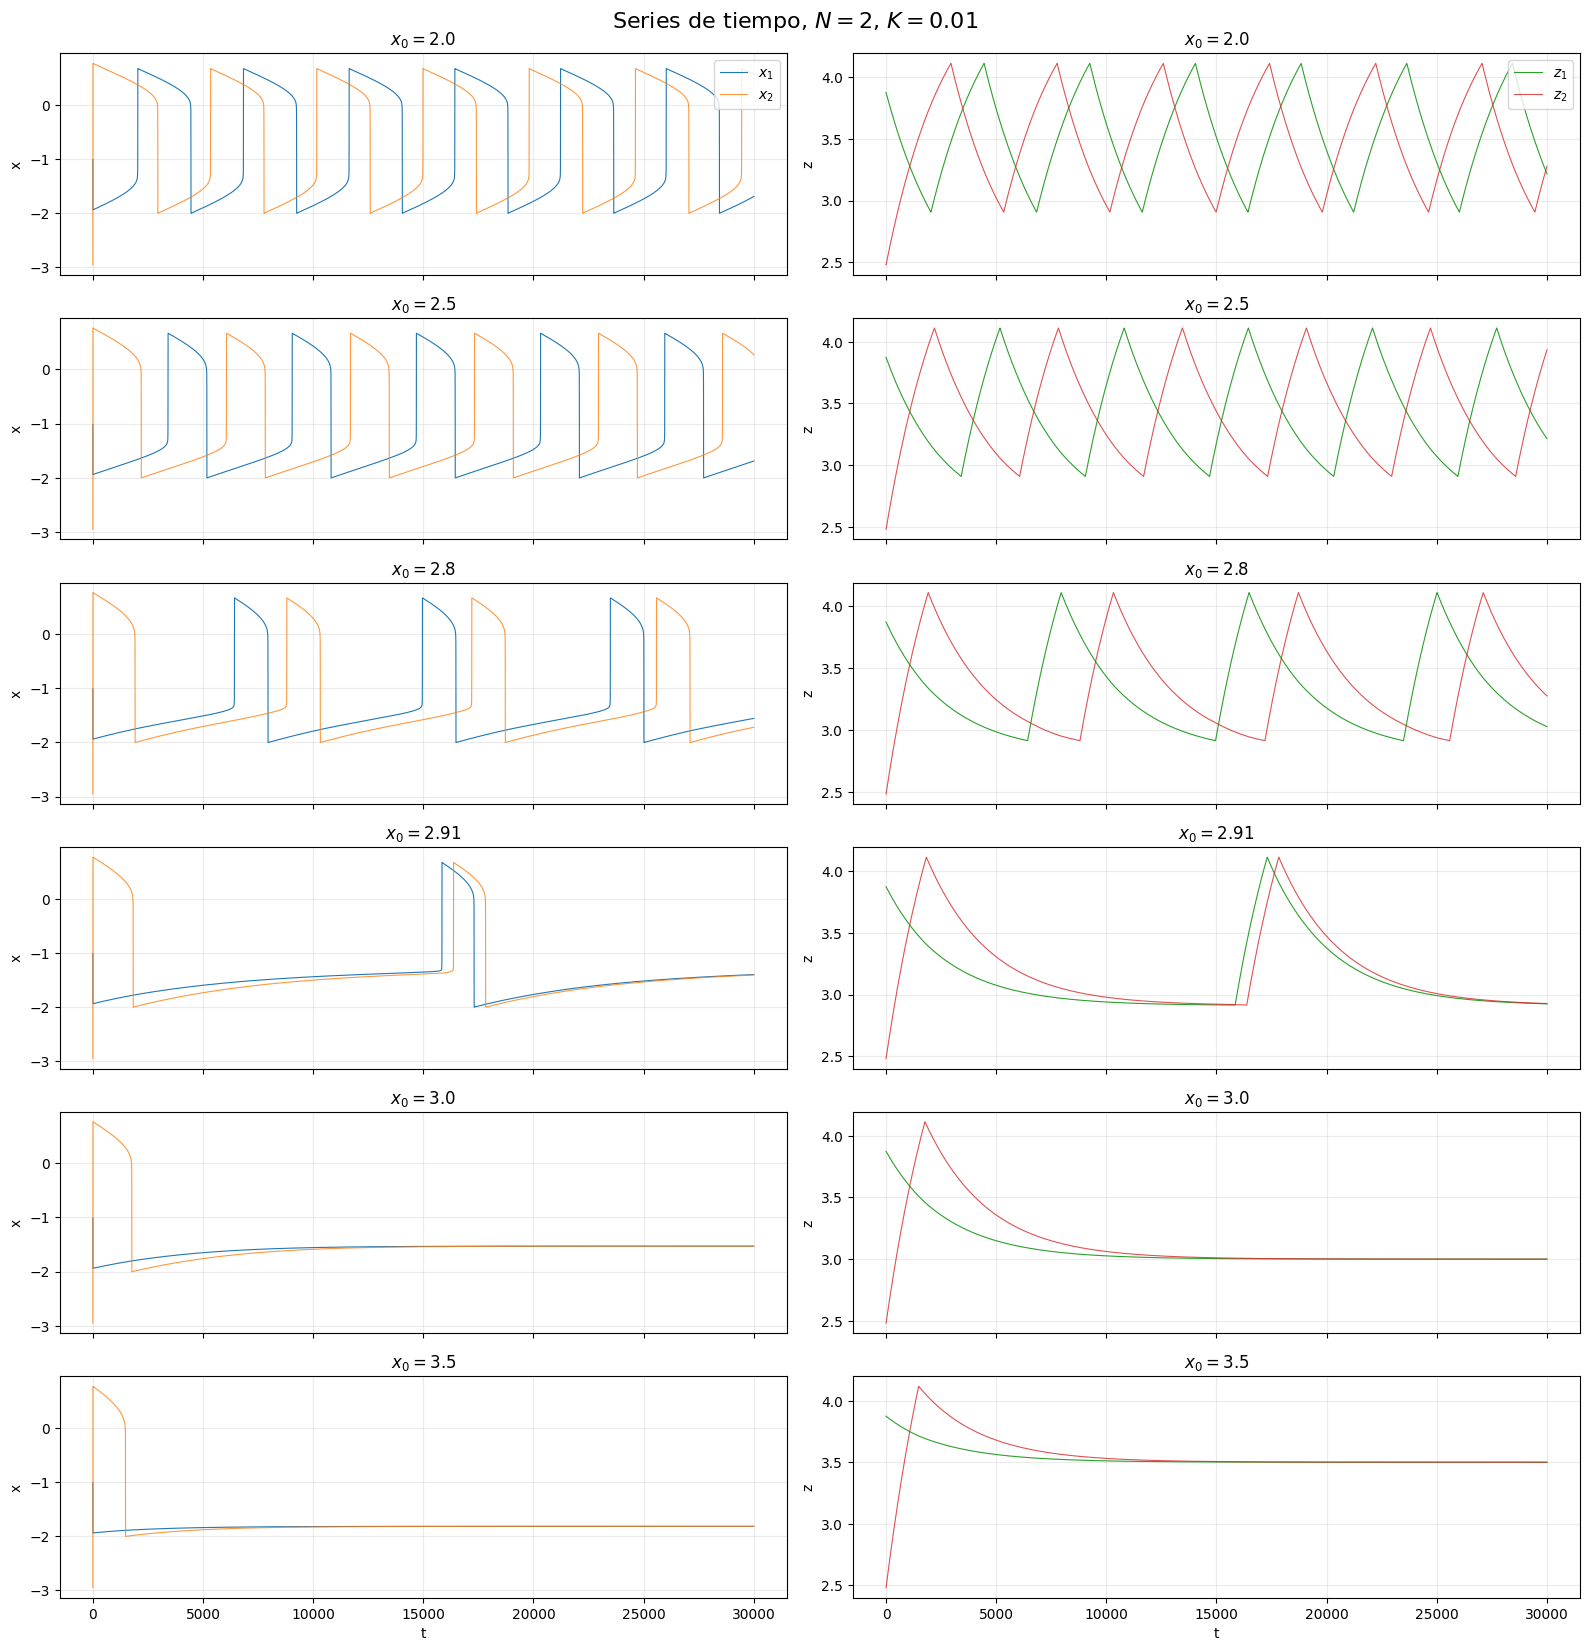

In [ ]:
x0_lista = [2.0, 2.5, 2.8, 2.91, 3.0, 3.5]   # oscilatorio, cercano a 2.91 y sano

for K in [0.01]:
    series_tiempo_N2(K, x0_lista)

- $K=0.5$.

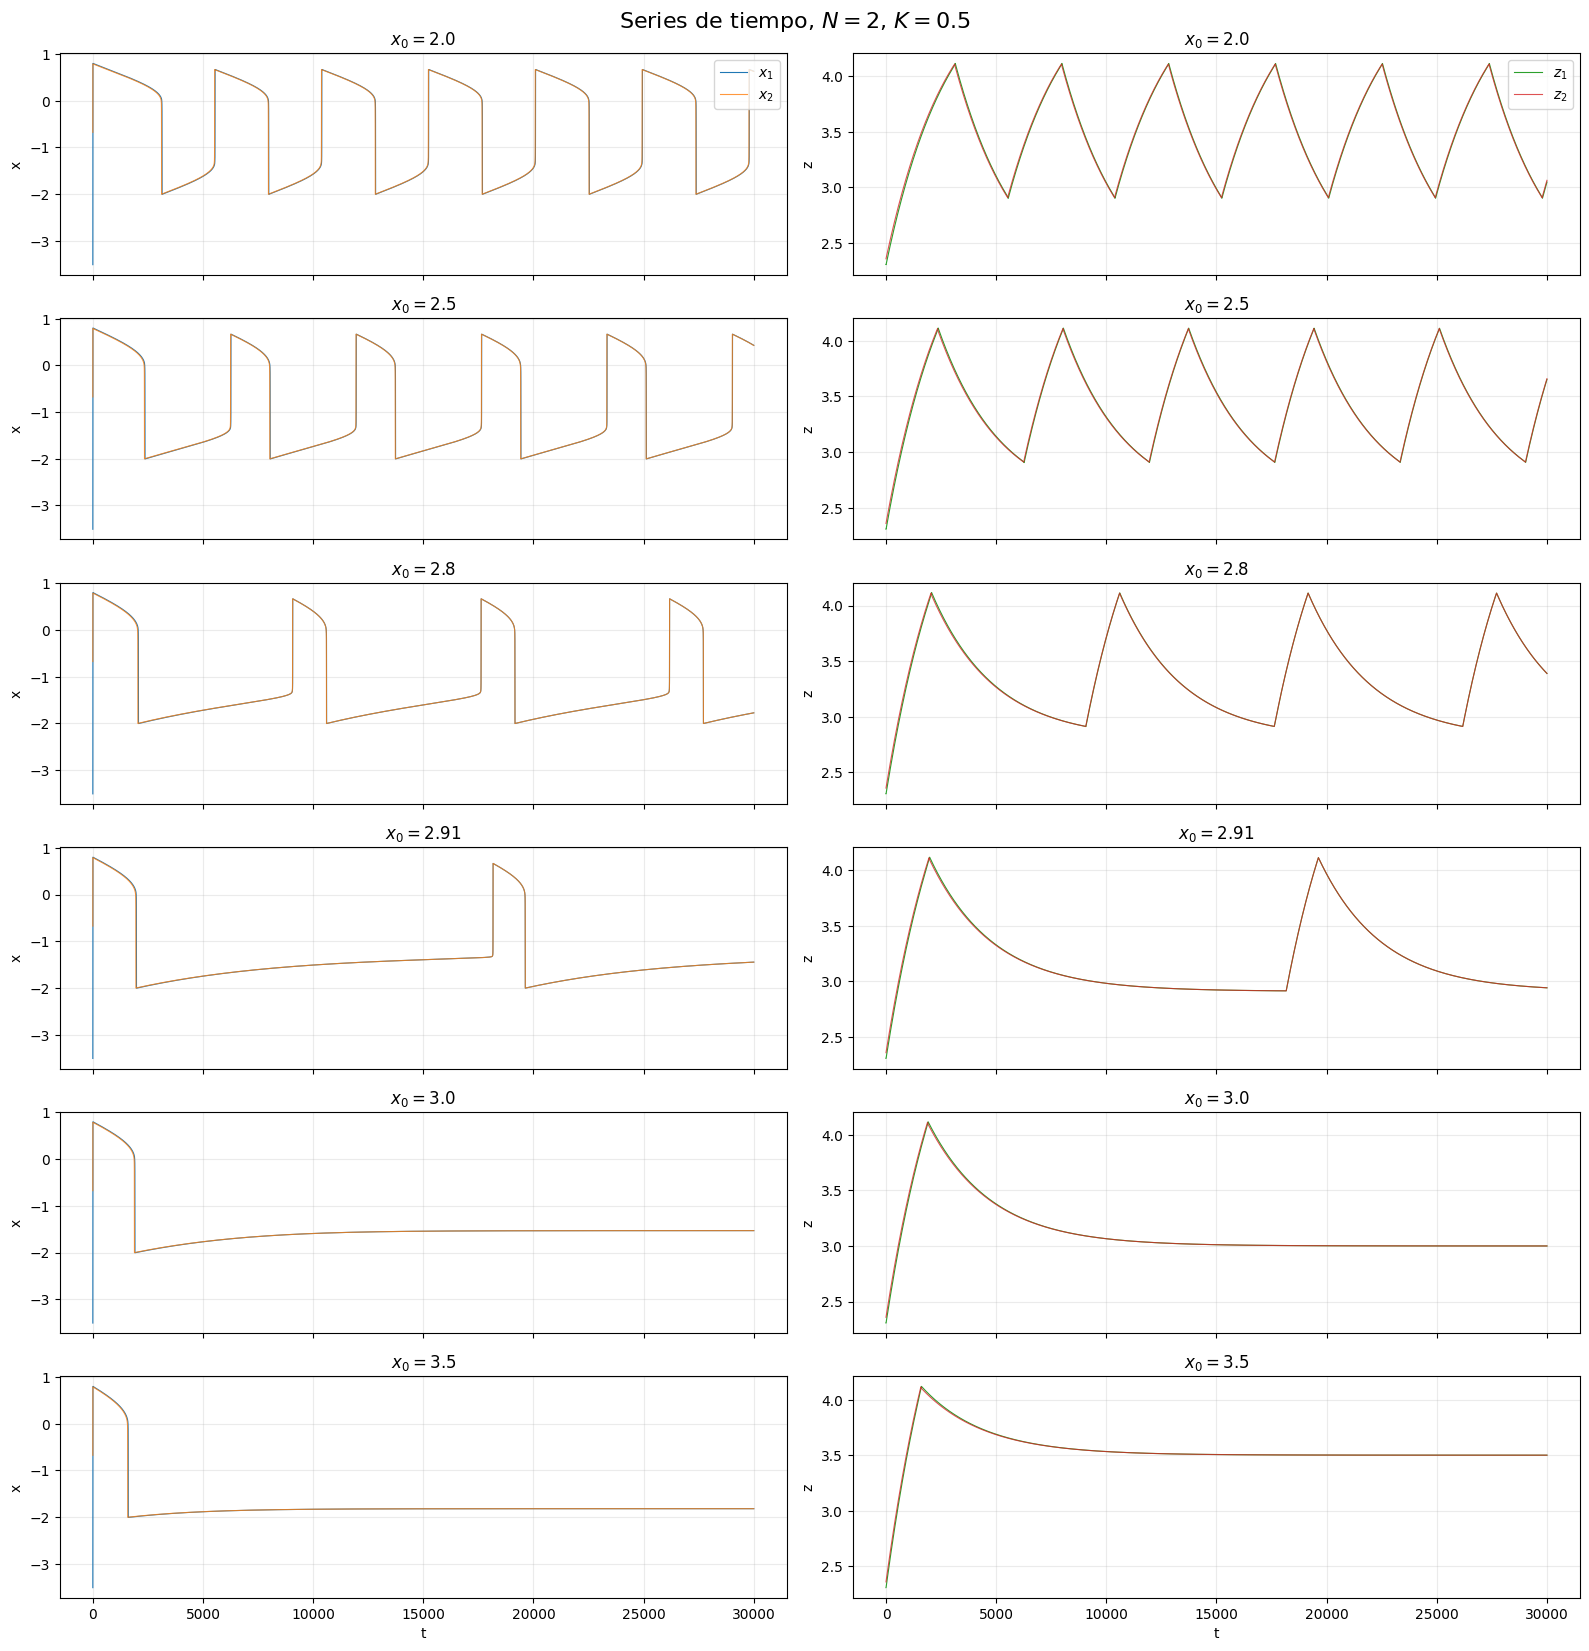

In [ ]:
x0_lista = [2.0, 2.5, 2.8, 2.91, 3.0, 3.5]

for K in [0.5]:
    series_tiempo_N2(K, x0_lista)

- $K=5$.

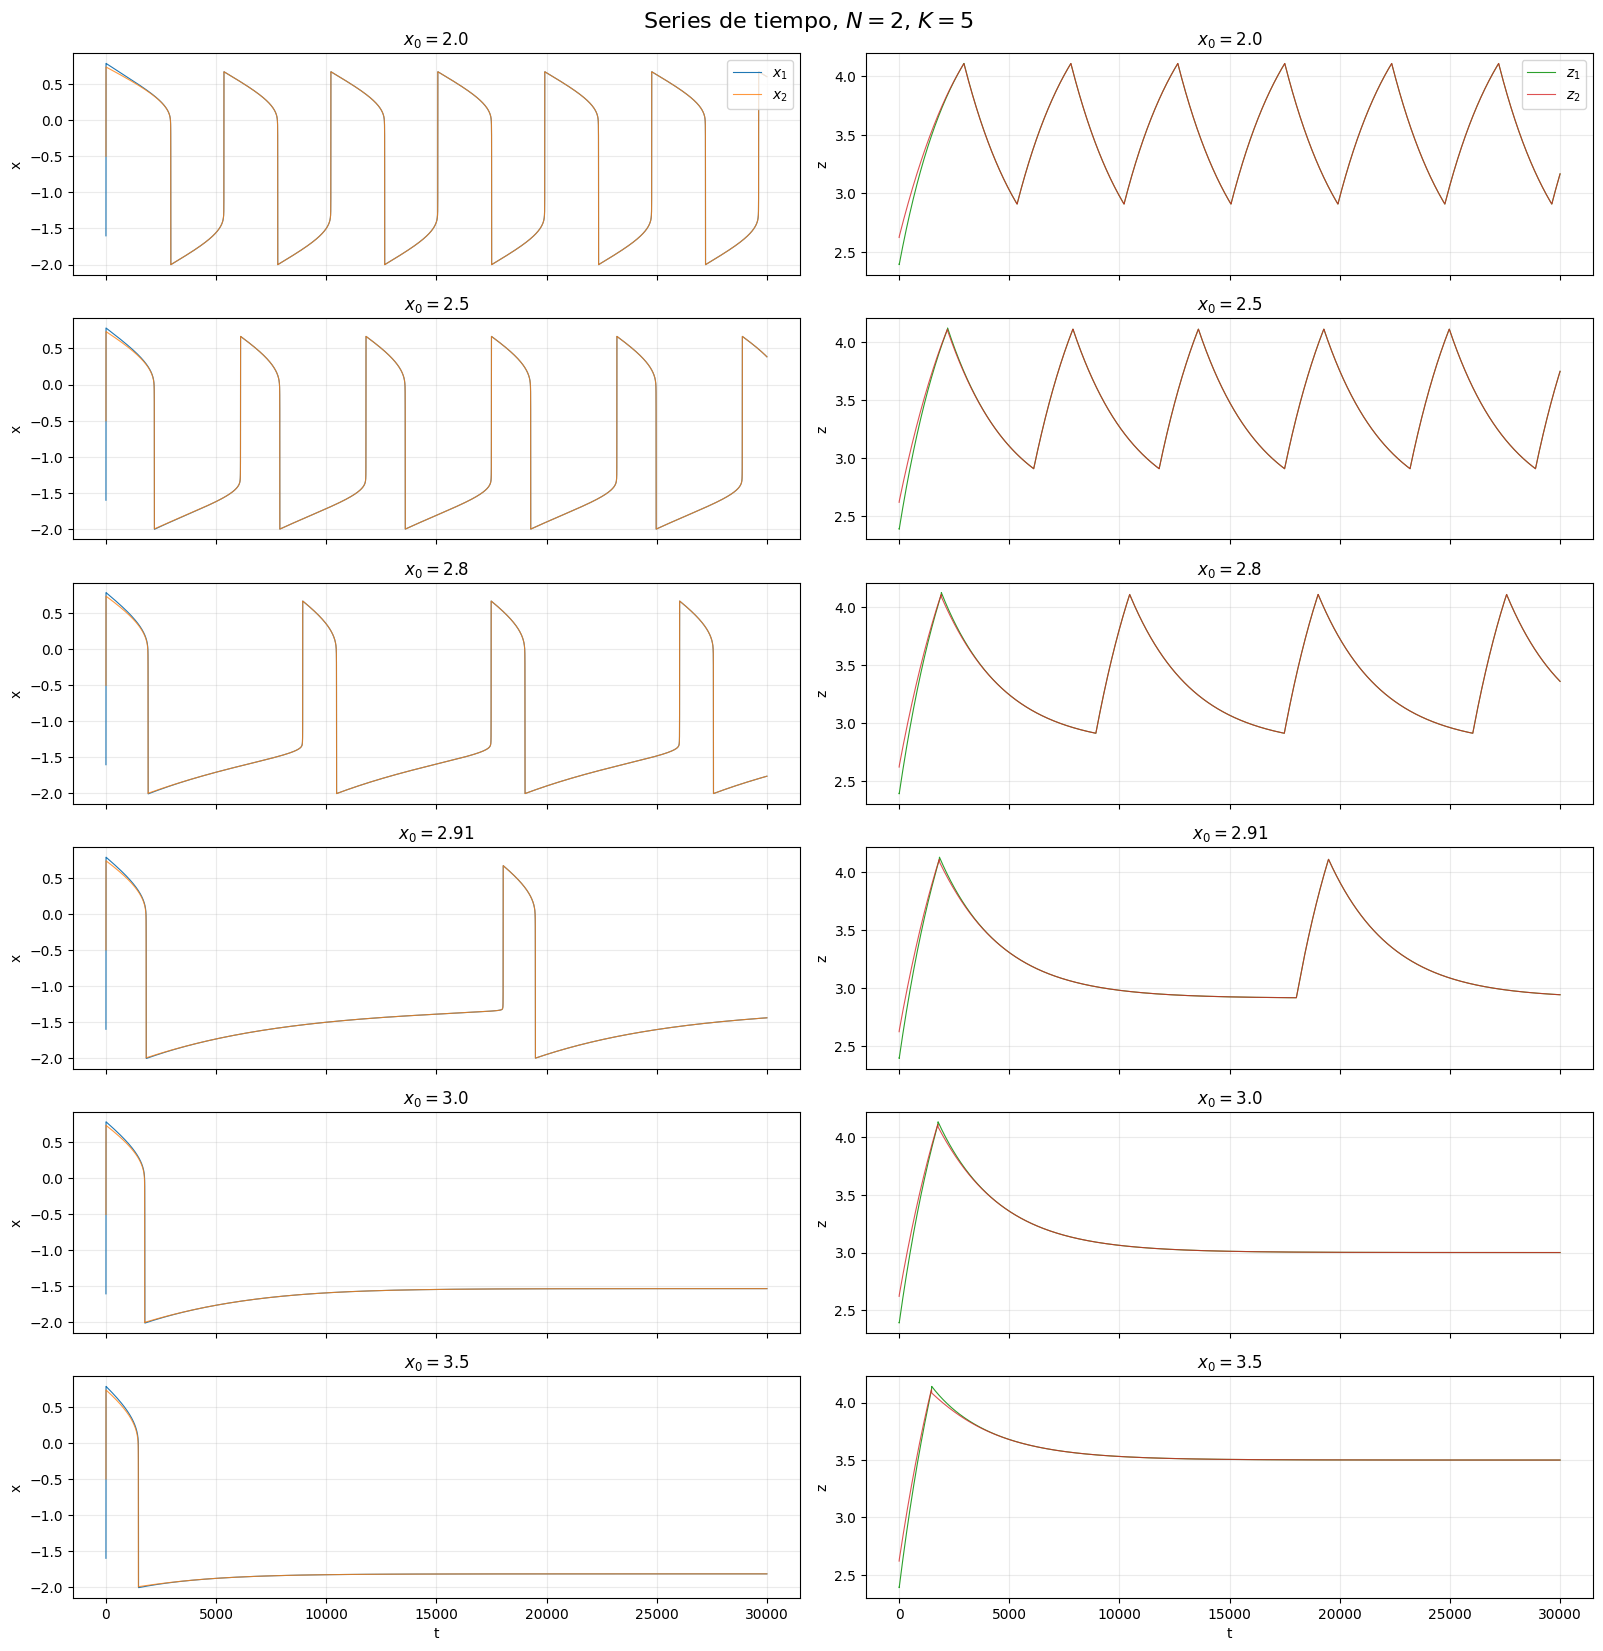

In [ ]:
x0_lista = [2.0, 2.5, 2.8, 2.91, 3.0, 3.5]
for K in [5]:
    series_tiempo_N2(K, x0_lista)

# **Creamos funciones para las series de tiempo**.

In [ ]:
def series_pares(K, pares, T=30000, dt=1.0, y0=None):
    n = len(pares)
    fig, axes = plt.subplots(n, 2, figsize=(16, 2.8 * n), sharex=True)
    axes = np.atleast_2d(axes)
    for i, (a, b) in enumerate(pares):
        t, x1, x2, z1, z2 = simular_N2(a, b, K, T=T, y0=y0, dt=dt)
        axes[i, 0].plot(t, x1, lw=0.9, label='$x_1$')
        axes[i, 0].plot(t, x2, lw=0.9, ls='--', label='$x_2$')
        axes[i, 0].set_ylabel('x')
        axes[i, 0].set_title(rf'$x_{{0,1}}={a}$, $x_{{0,2}}={b}$, $K={K}$')
        axes[i, 1].plot(t, z1, 'C2', lw=0.9, label='$z_1$')
        axes[i, 1].plot(t, z2, 'C3', lw=0.9, ls='--', label='$z_2$')
        axes[i, 1].set_ylabel('z')
        for c in (0, 1):
          axes[i, c].grid(alpha=0.25)
    axes[0, 0].legend(loc='upper right'); axes[0, 1].legend(loc='upper right')
    axes[-1, 0].set_xlabel('t'); axes[-1, 1].set_xlabel('t')
    plt.tight_layout()
    plt.show()

# **Incluimos las dinámicas rectangulares dadas por $h(x(t))$**.

In [ ]:
def series_h_N2(K, pares, T=30000, dt=1.0, y0=None, mostrar_z=True):
    n = len(pares)
    fig, axes = plt.subplots(n, 2, figsize=(16, 2.9 * n), sharex=True)
    axes = np.atleast_2d(axes)

    for i, (a, b) in enumerate(pares):
        y0_i = y0(a, b) if callable(y0) else y0
        t, x1, x2, z1, z2 = simular_N2(a, b, K, T=T, y0=y0_i, dt=dt)

        h1 = h(x1, a)
        h2 = h(x2, b)

        axes[i, 0].plot(t, x1, lw=1.0, label='$x_1(t)$')
        axes[i, 0].plot(t, x2, lw=1.0, ls='--', label='$x_2(t)$')
        axes[i, 0].set_ylabel('x')
        axes[i, 0].set_title(rf'$x_{{0,1}}={a}$, $x_{{0,2}}={b}$, $K={K}$')

        axes[i, 1].plot(t, h1, lw=1.3, label='$h(x_1(t))$')
        axes[i, 1].plot(t, h2, lw=1.3, ls='--', label='$h(x_2(t))$')
        if mostrar_z:
            axes[i, 1].plot(t, z1, 'C0', lw=0.8, alpha=0.45, label='$z_1$')
            axes[i, 1].plot(t, z2, 'C1', lw=0.8, alpha=0.45, label='$z_2$')
        axes[i, 1].set_ylabel('h(x)')
        axes[i, 1].set_title('Onda rectangular $h(x(t))$')

        for c in (0, 1):
            axes[i, c].grid(alpha=0.25)

    axes[0, 0].legend(loc='upper right'); axes[0, 1].legend(loc='upper right', ncol=2, fontsize=8)
    axes[-1, 0].set_xlabel('t')
    axes[-1, 1].set_xlabel('t')
    plt.tight_layout()
    plt.show()

# **Dinámica de la Región II, Epileptogénica + Sana y distintos valores de $K$**.

### Condiciones Iniciales Fijas, para poder comparar ambos gráficos.

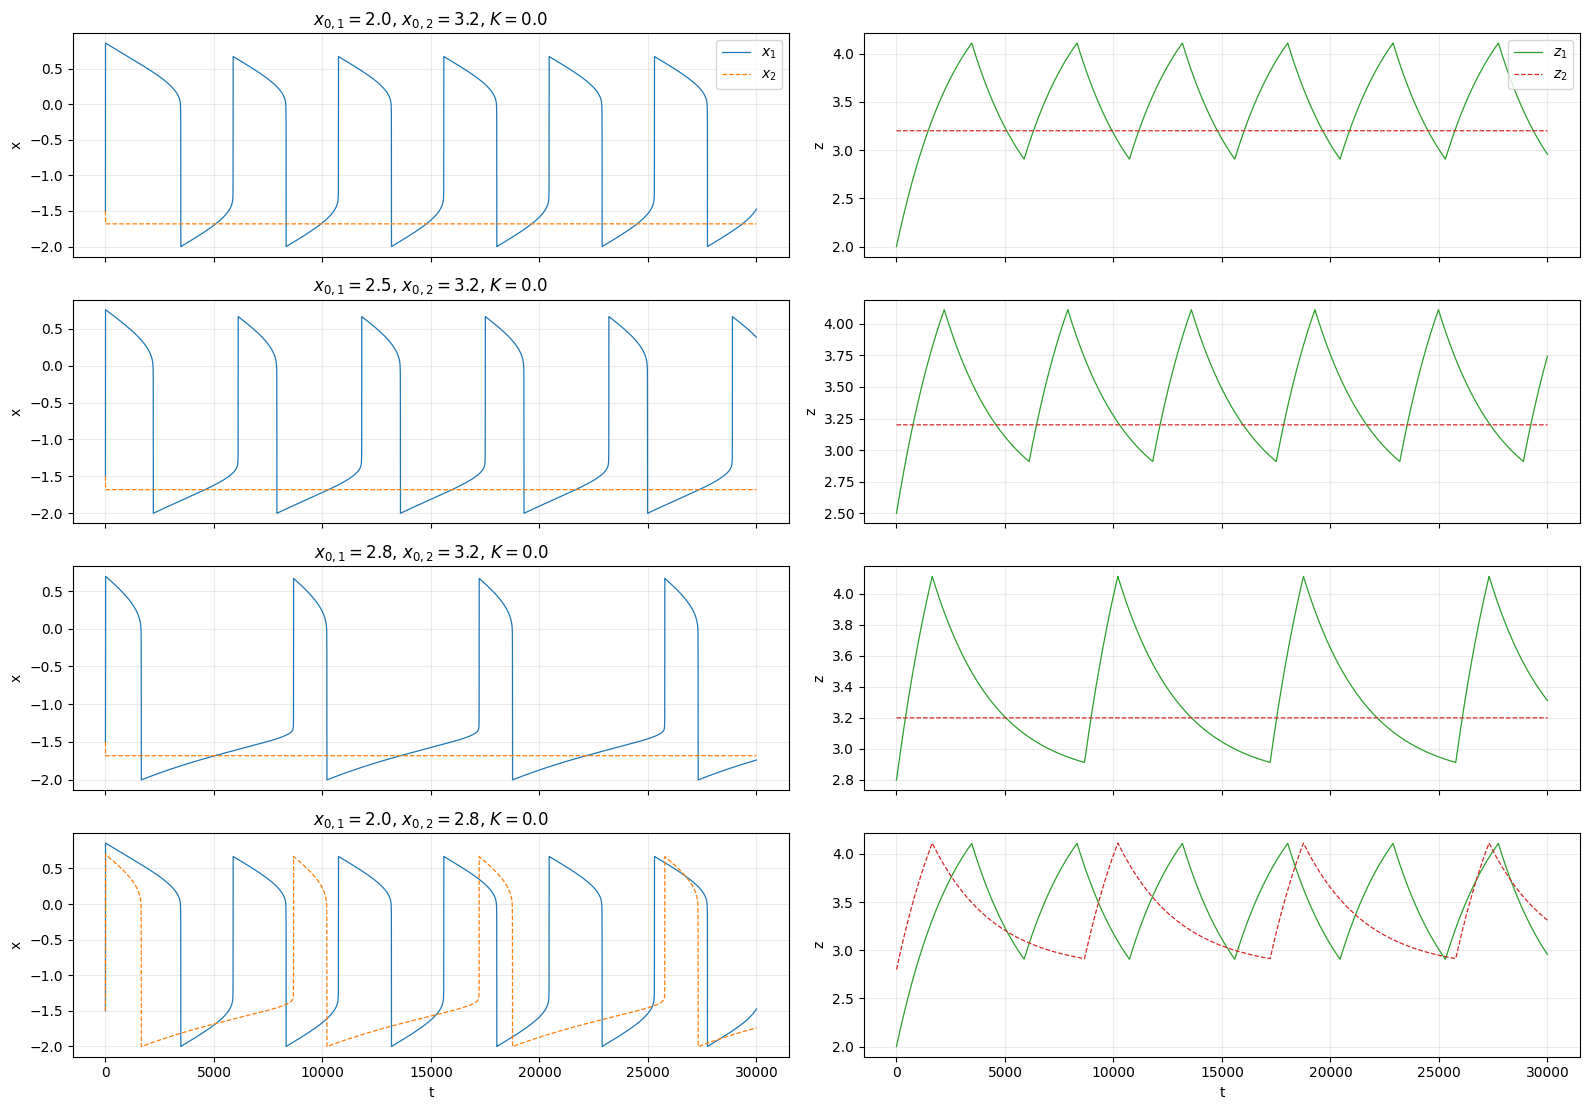

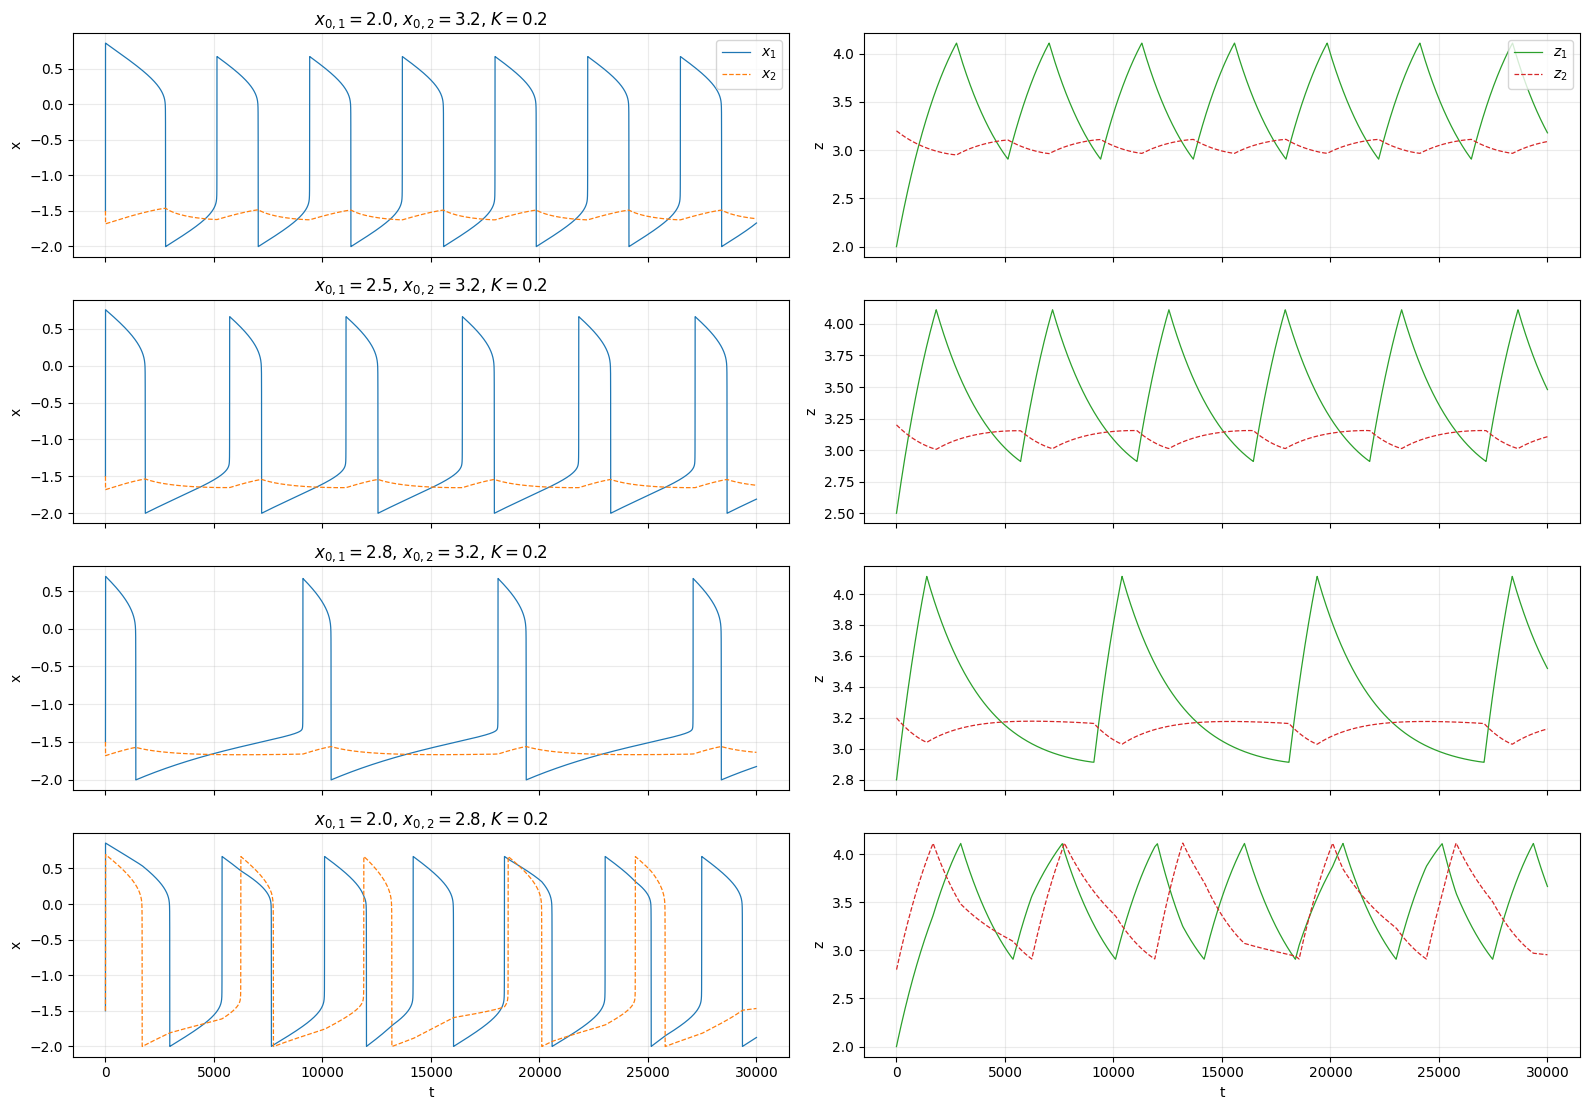

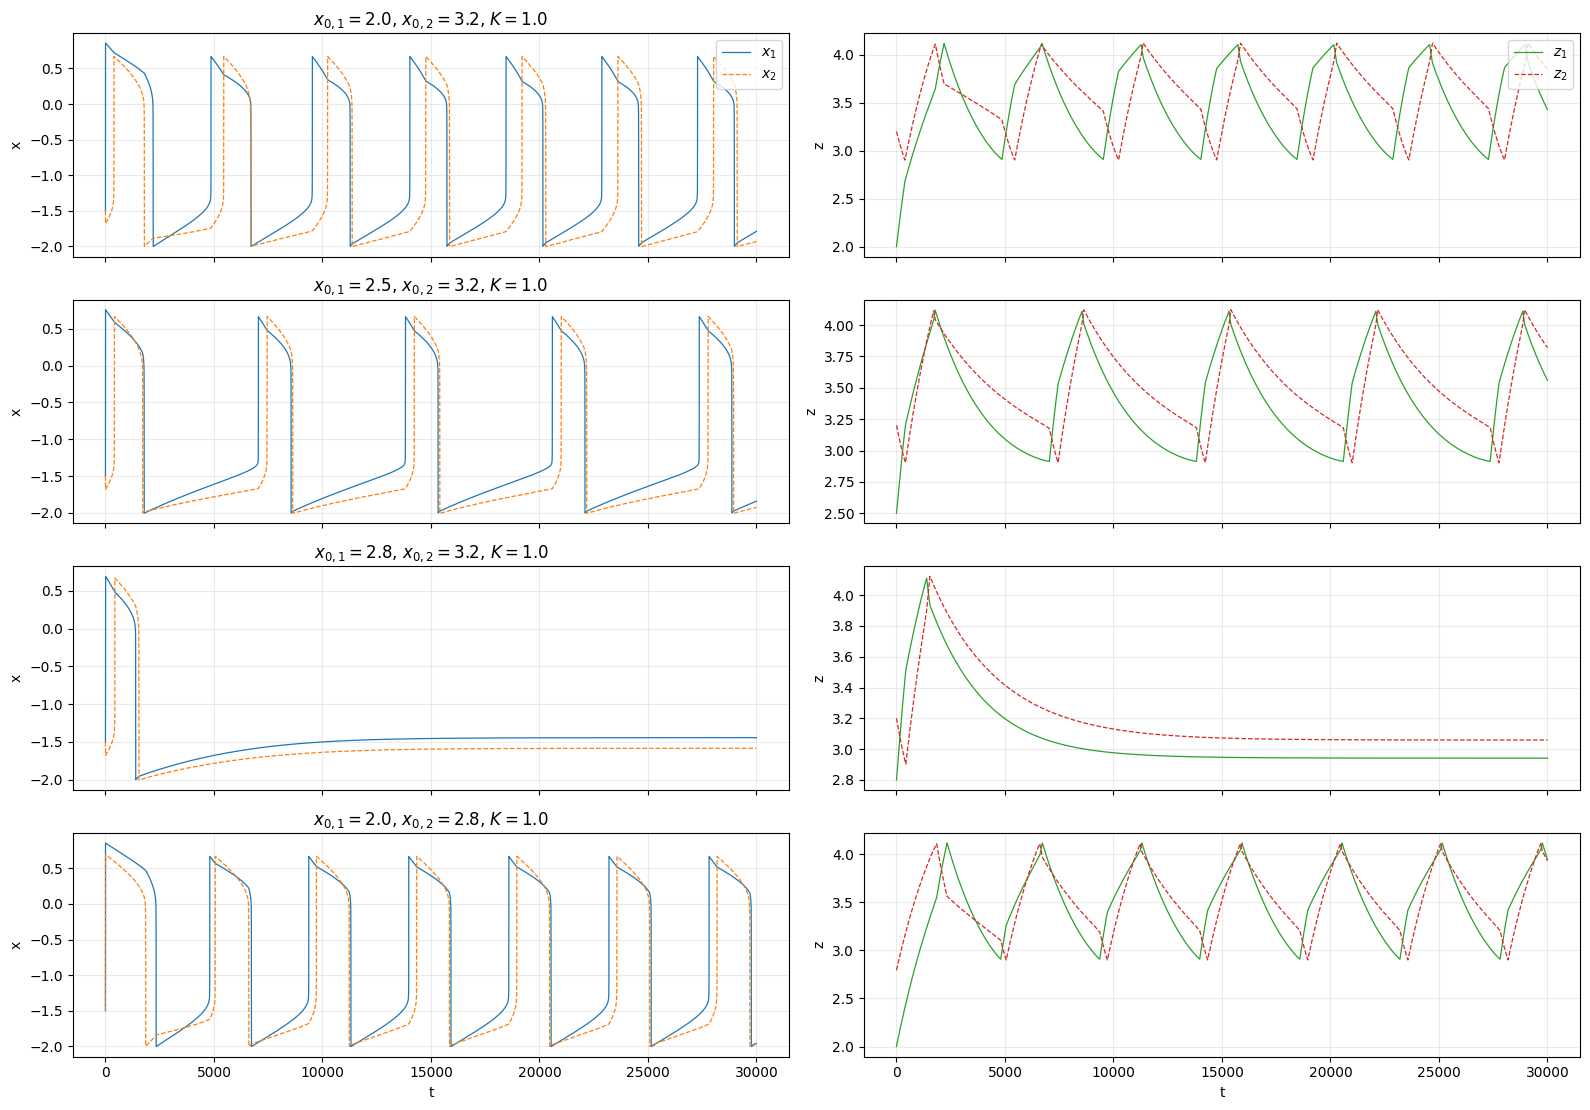

In [ ]:
pares = [(2.0, 3.2), (2.5, 3.2), (2.8, 3.2), (2.0, 2.8)]

for K in [0.0, 0.2, 1.0]:
    series_pares(K, pares)

# **Visualizamos $z(t)$ y $h(x(t))$ conjuntamente**.

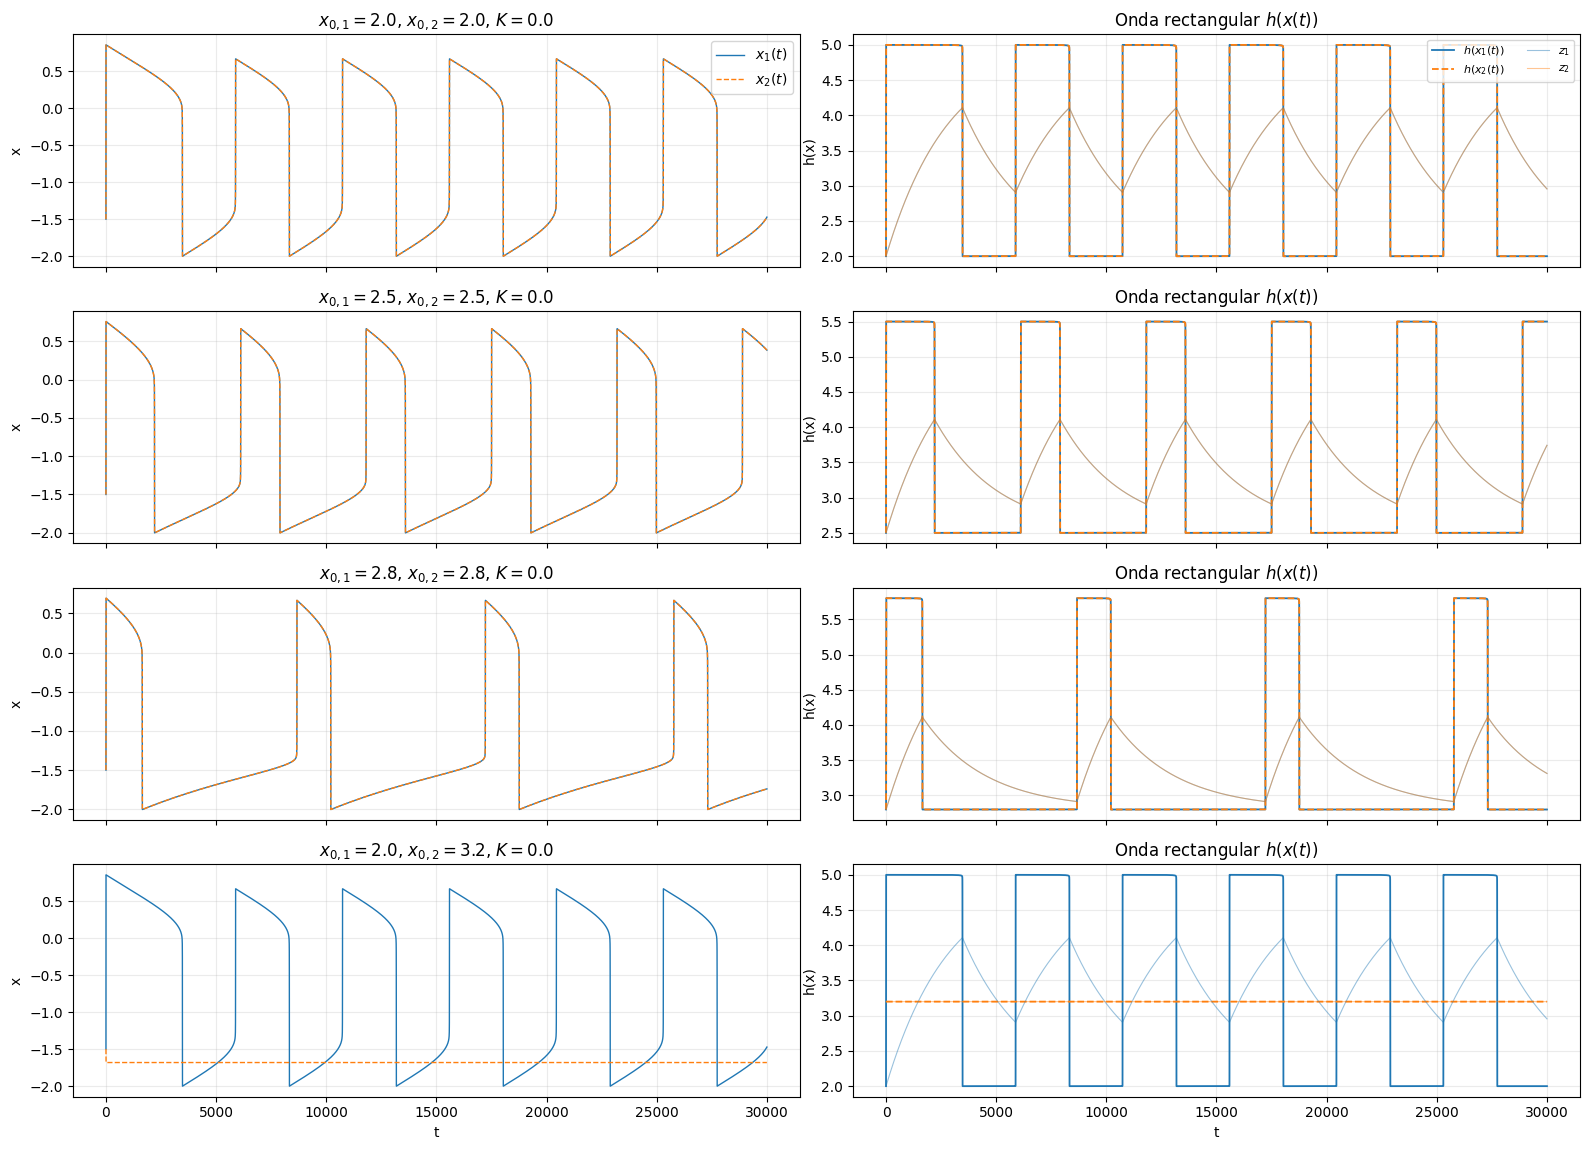

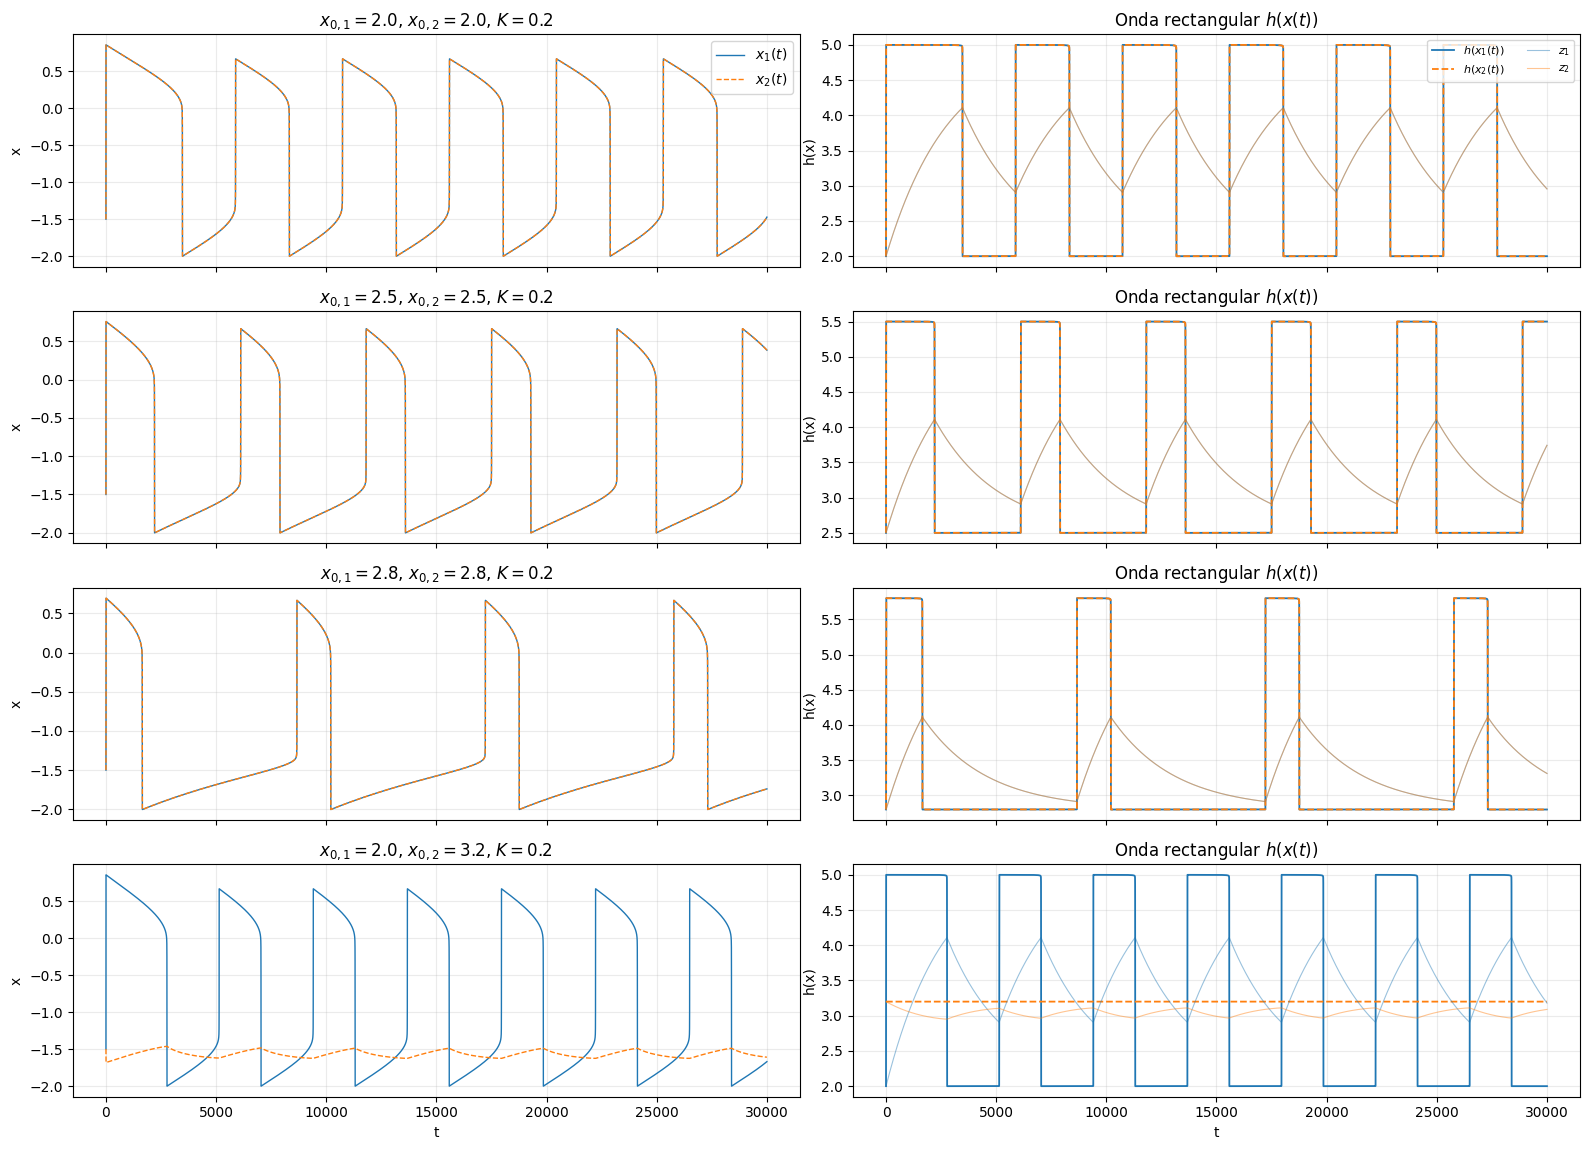

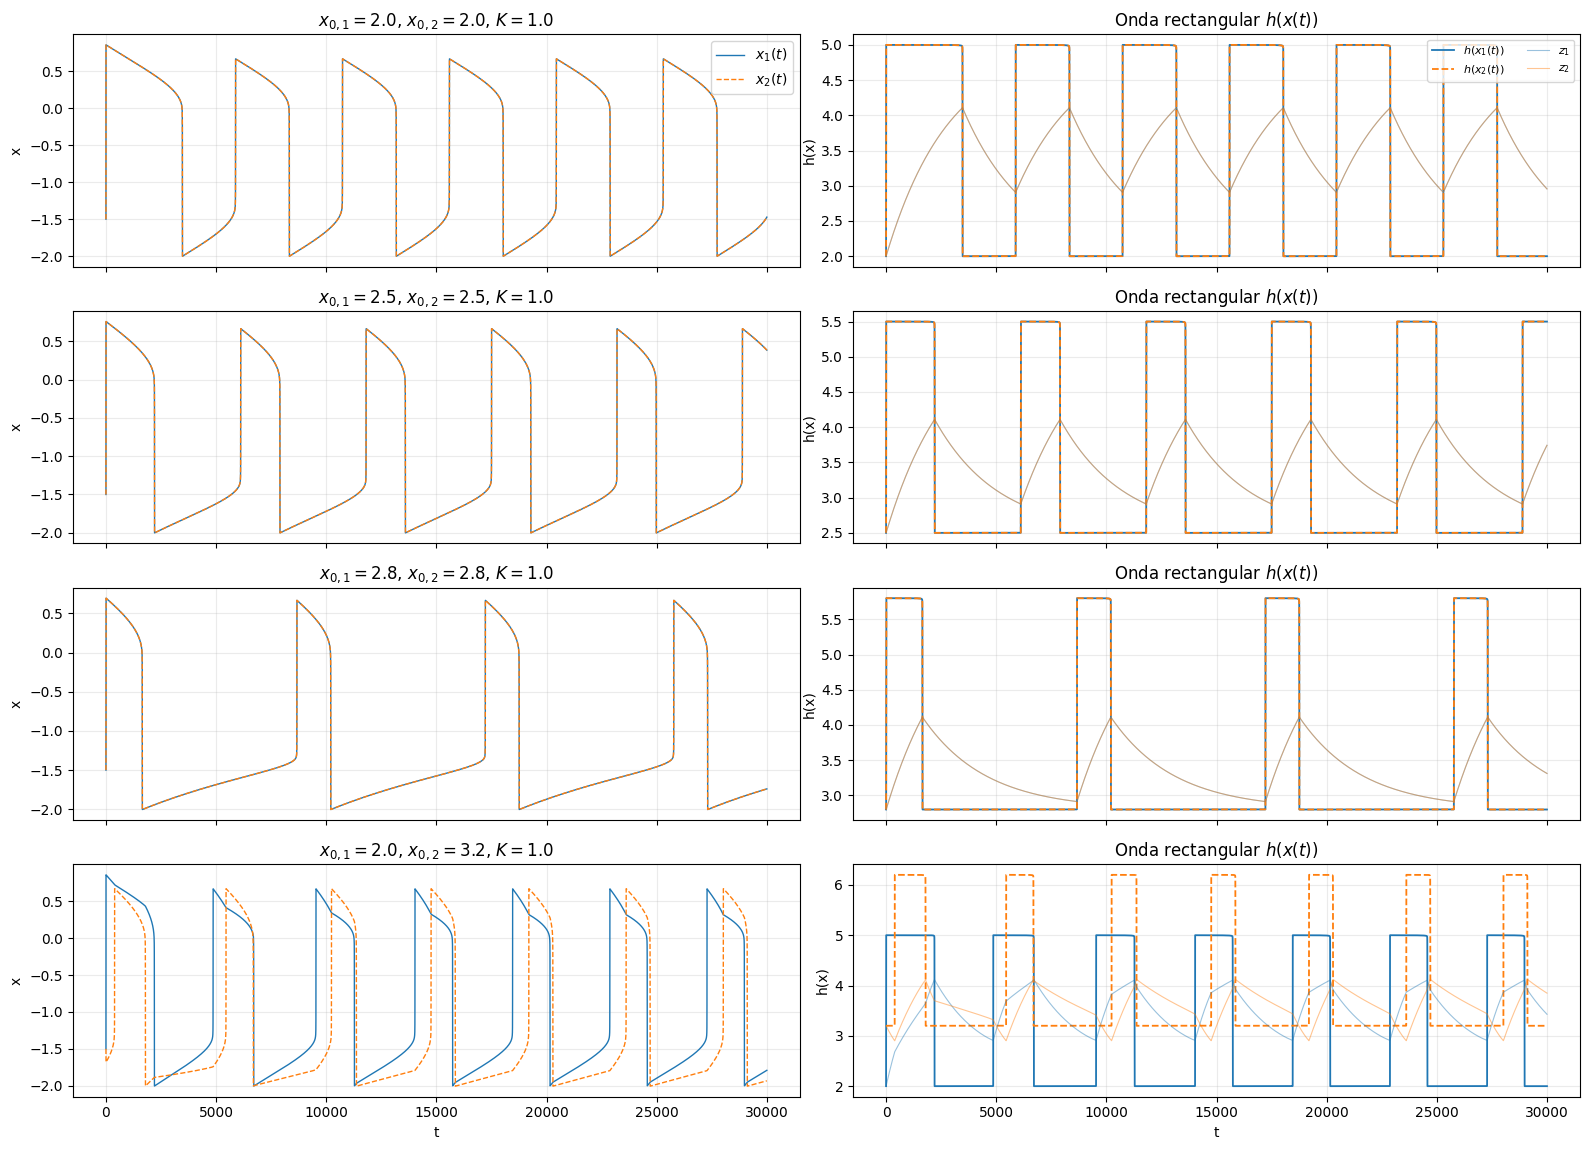

In [ ]:
pares = [(2.0, 2.0), (2.5, 2.5), (2.8, 2.8), (2.0, 3.2)]

for K in [0.0, 0.2, 1.0]:
    series_h_N2(K, pares)

In [ ]:
def x_y_h(a, b, K, T=30000, dt=0.5, y0=None, t_ini=0):
    t, x1, x2, _, _ = simular_N2(a, b, K, T=T, y0=y0, dt=dt)
    m = t >= t_ini

    fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

    ax[0].plot(t[m], x1[m], lw=1.2, label='$x_1(t)$')
    ax[0].plot(t[m], x2[m], lw=1.2, ls='--', label='$x_2(t)$')
    ax[0].set_ylabel('x')
    ax[0].set_title(rf'$x_{{0,1}}={a}$, $x_{{0,2}}={b}$, $K={K}$')
    ax[0].legend(loc='upper right'); ax[0].grid(alpha=0.25)

    ax[1].plot(t[m], h(x1[m], a), lw=1.4, label='$h(x_1(t))$')
    ax[1].plot(t[m], h(x2[m], b), lw=1.4, ls='--', label='$h(x_2(t))$')
    ax[1].set_ylabel('h(x)'); ax[1].set_xlabel('t')
    ax[1].legend(loc='upper right'); ax[1].grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

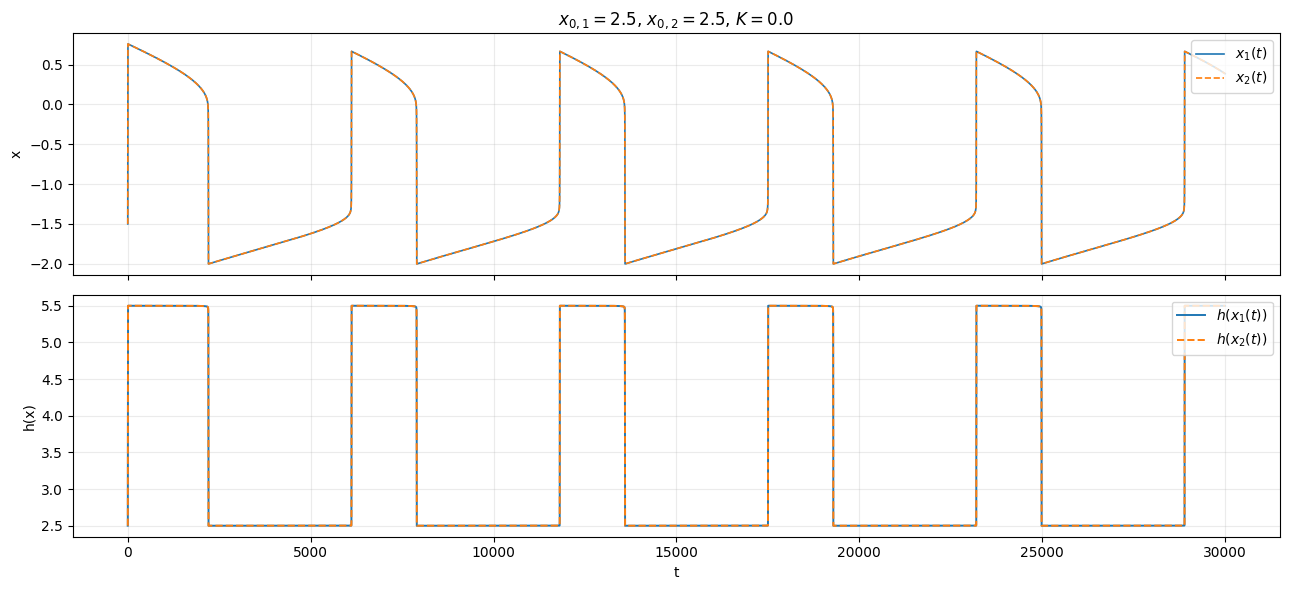

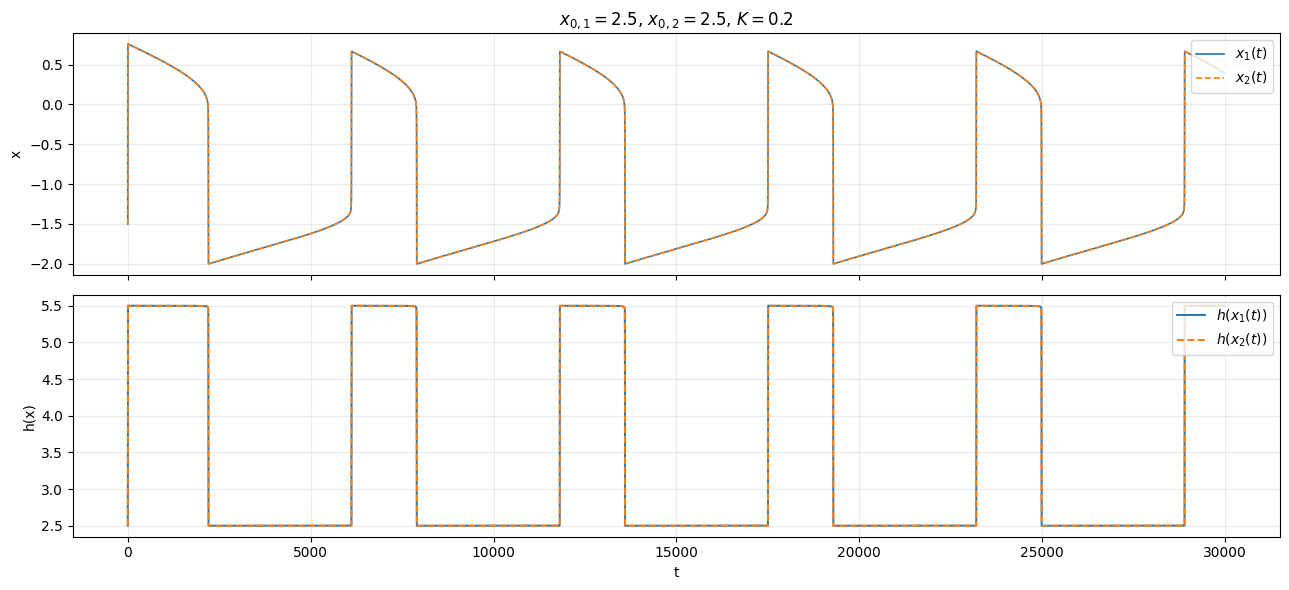

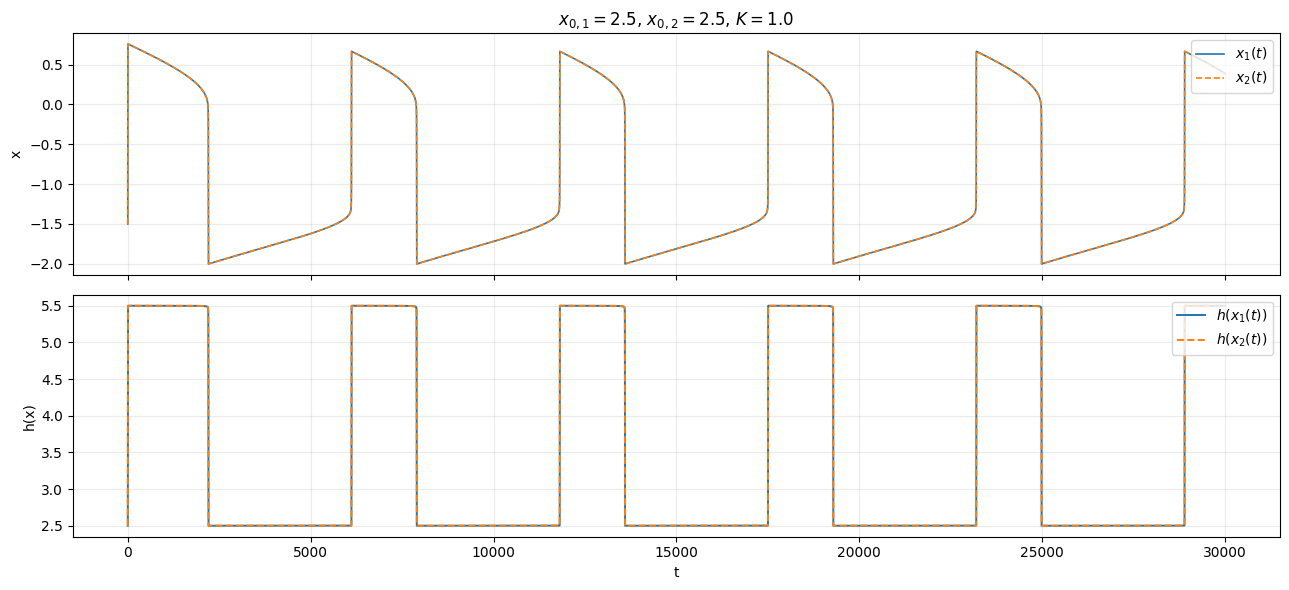

In [ ]:
for K in [0.0, 0.2, 1.0]:
    x_y_h(2.5, 2.5, K)

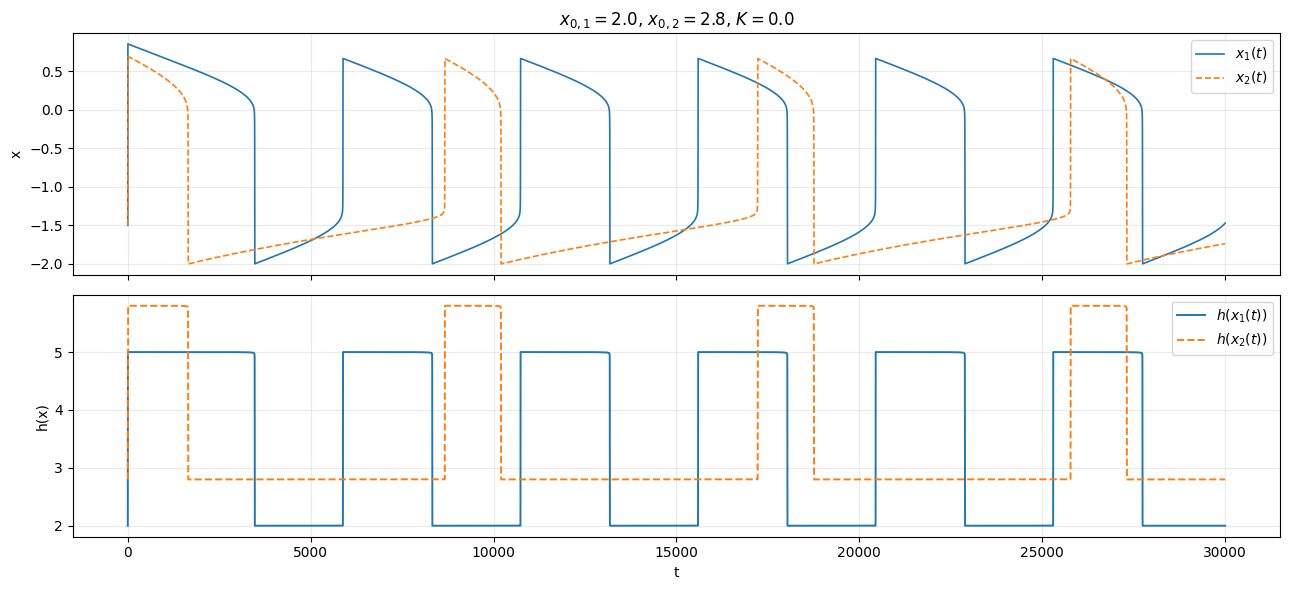

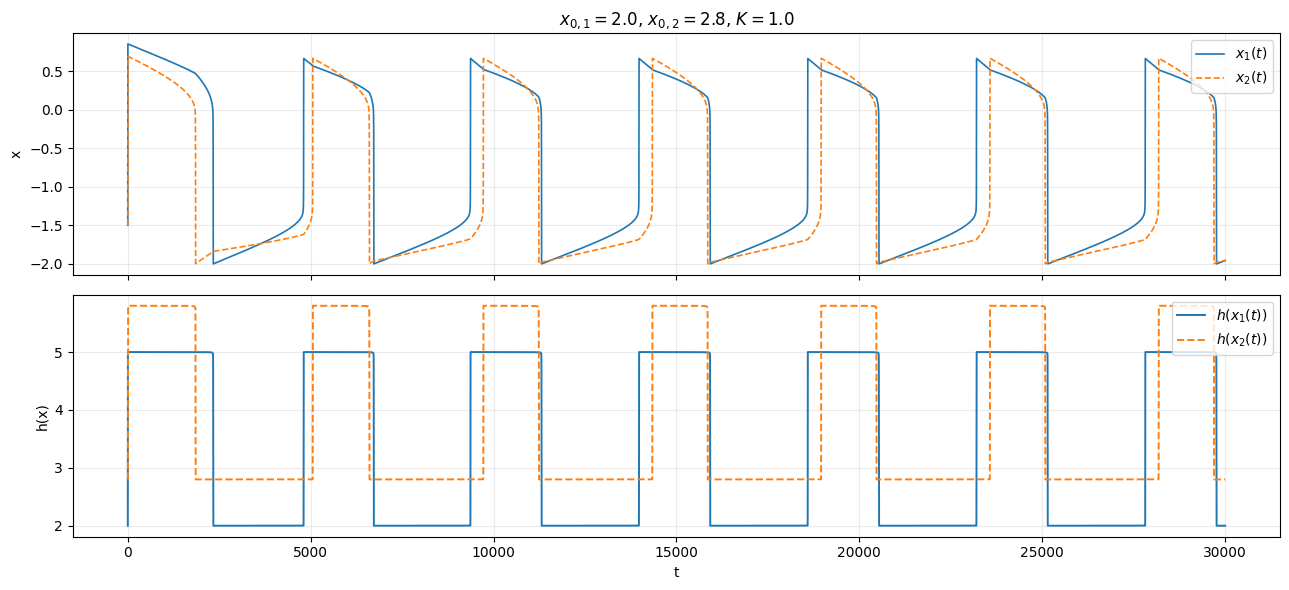

In [ ]:
for K in [0.0, 1.0]:
    x_y_h(2.0, 2.8, K)

In [ ]:
def x_z_h(a, b, K, T=30000, dt=0.5, y0=None, t_ini=0):
    t, x1, x2, z1, z2 = simular_N2(a, b, K, T=T, y0=y0, dt=dt)
    m = t >= t_ini

    fig, ax = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

    # Fila 1: x1(t), x2(t)
    ax[0].plot(t[m], x1[m], lw=1.2, label='$x_1(t)$')
    ax[0].plot(t[m], x2[m], lw=1.2, ls='--', label='$x_2(t)$')
    ax[0].set_ylabel('x')
    ax[0].set_title(rf'$x_{{0,1}}={a}$, $x_{{0,2}}={b}$, $K={K}$')
    ax[0].legend(loc='upper right'); ax[0].grid(alpha=0.25)

    # Fila 2: z1(t), z2(t)
    ax[1].plot(t[m], z1[m], 'C2', lw=1.2, label='$z_1(t)$')
    ax[1].plot(t[m], z2[m], 'C3', lw=1.2, ls='--', label='$z_2(t)$')
    ax[1].set_ylabel('z')
    ax[1].legend(loc='upper right'); ax[1].grid(alpha=0.25)

    # Fila 3: h(x1(t)), h(x2(t))
    ax[2].plot(t[m], h(x1[m], a), lw=1.4, label='$h(x_1(t))$')
    ax[2].plot(t[m], h(x2[m], b), lw=1.4, ls='--', label='$h(x_2(t))$')
    ax[2].set_ylabel('h(x)'); ax[2].set_xlabel('t')
    ax[2].legend(loc='upper right'); ax[2].grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

# **Con Condiciones Iniciales Aleatorias**

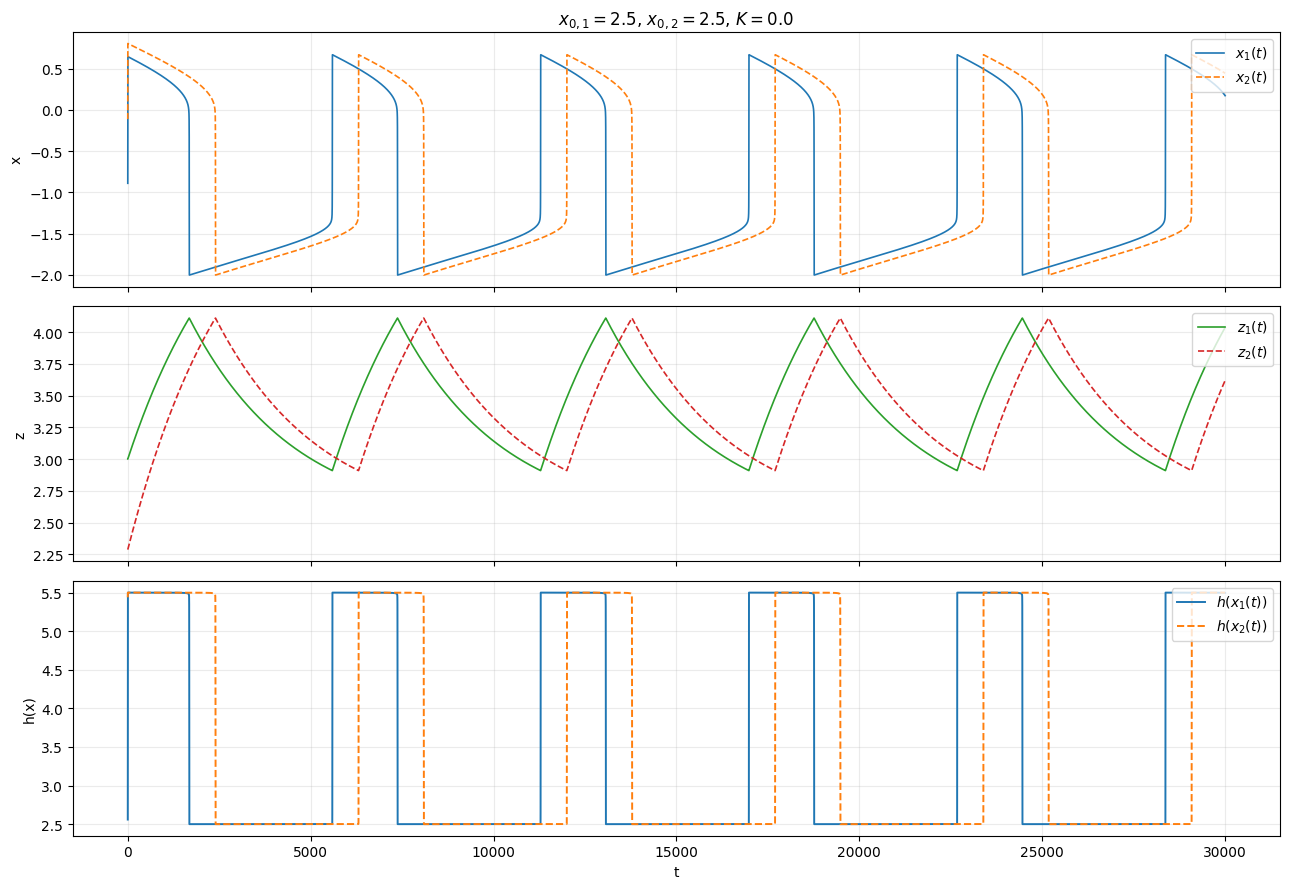

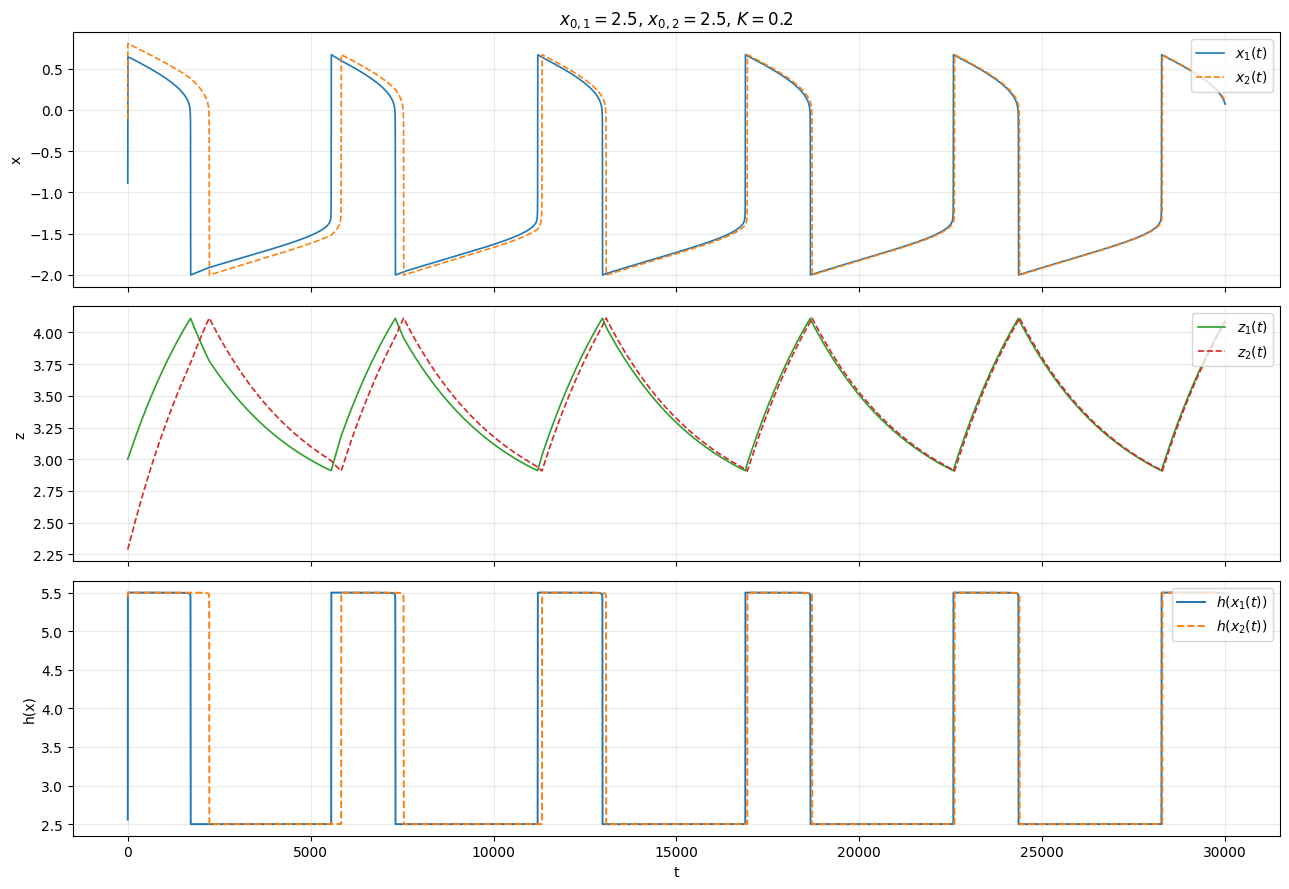

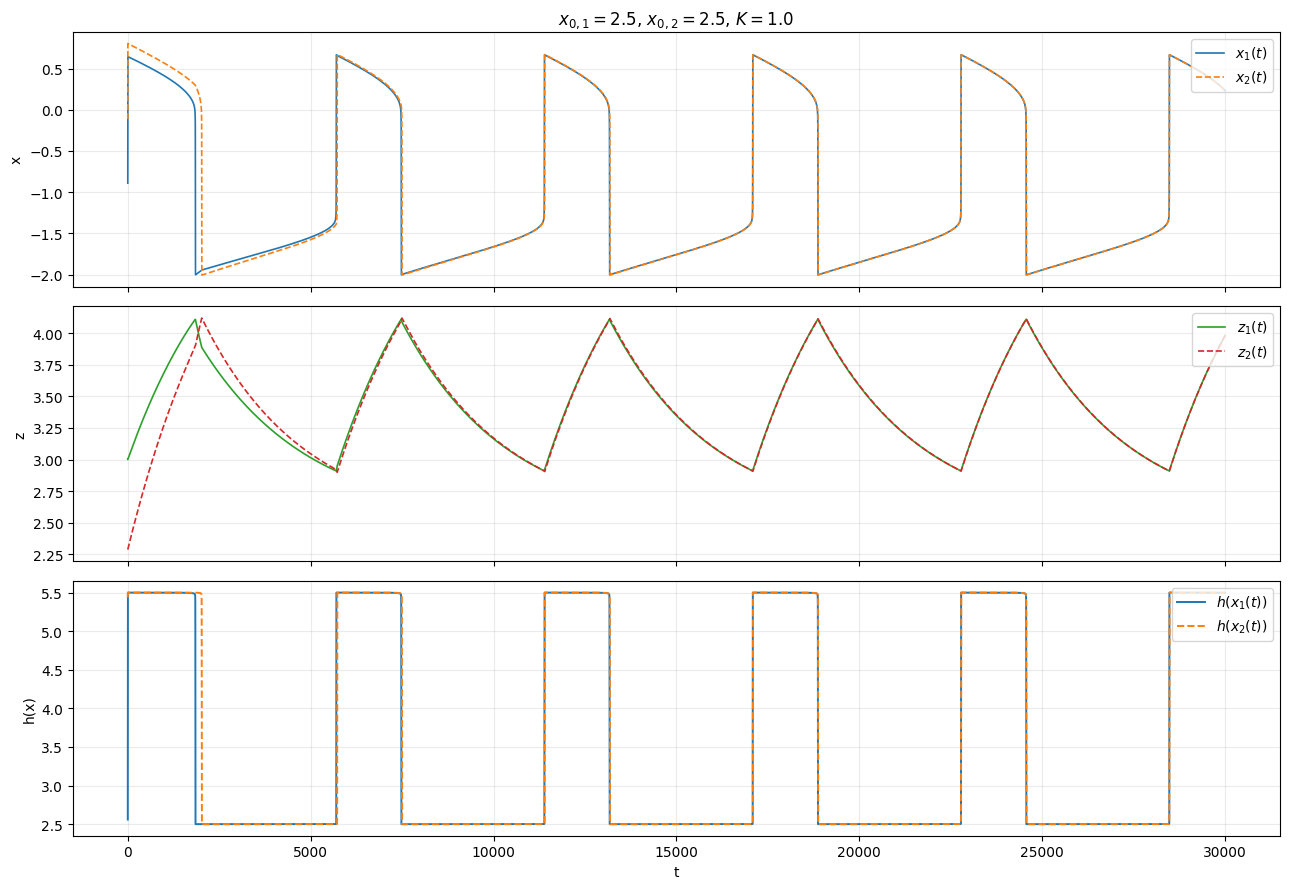

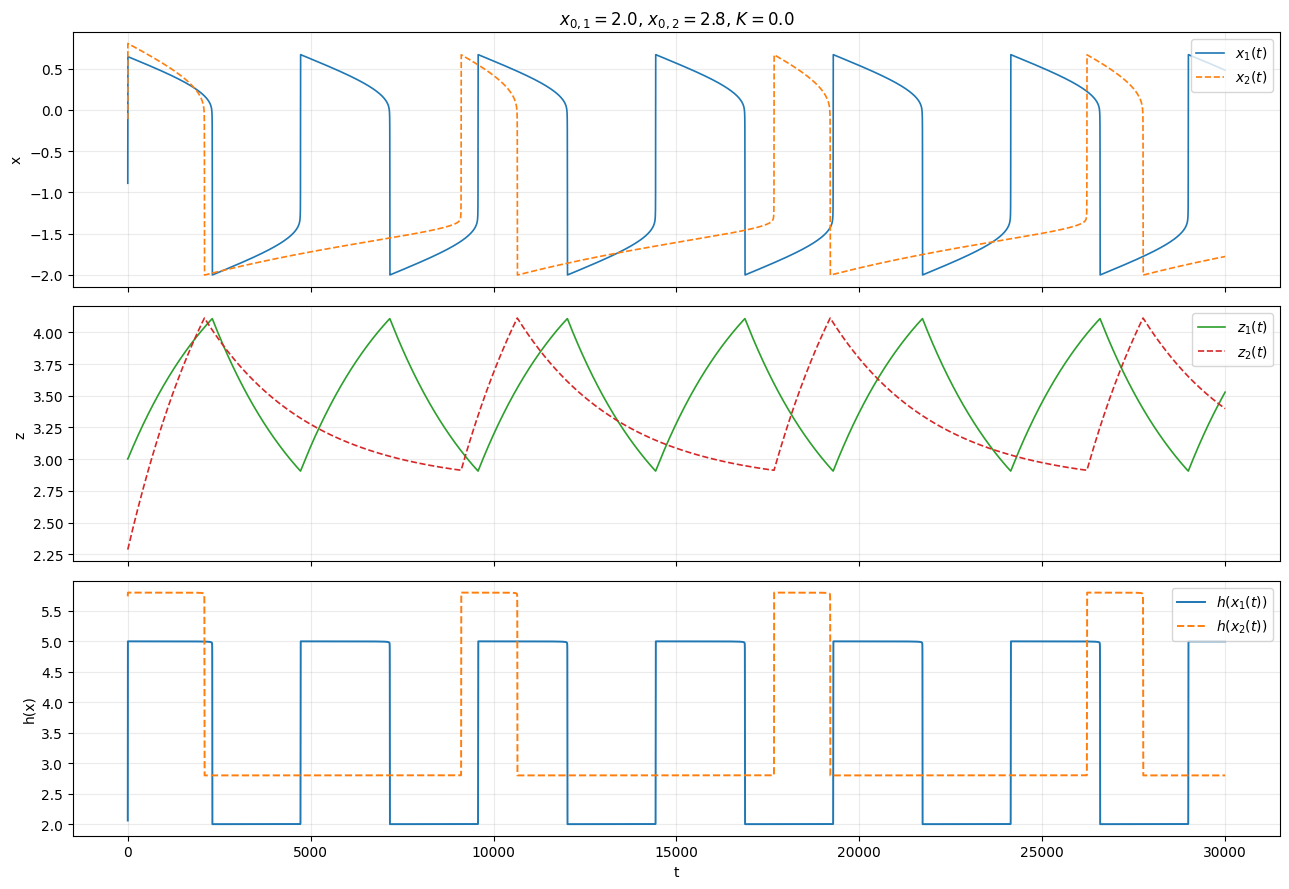

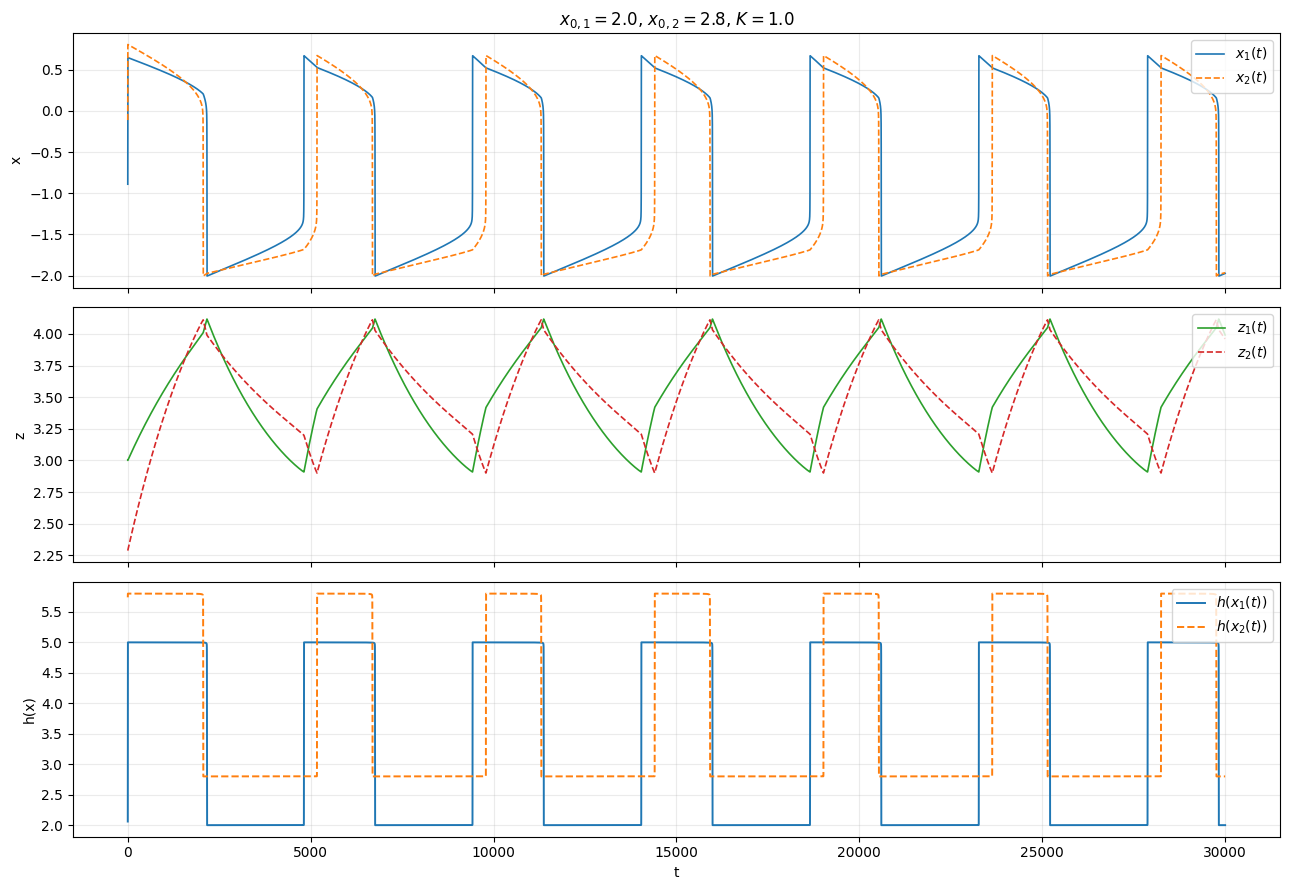

In [ ]:
x_ini, z_ini = cond_iniciales(2)
y0_fijo = (x_ini[0], x_ini[1], z_ini[0], z_ini[1])

for K in [0.0, 0.2, 1.0]:
    x_z_h(2.5, 2.5, K, y0=y0_fijo)

for K in [0.0, 1.0]:
    x_z_h(2.0, 2.8, K, y0=y0_fijo)

# **Mapas de Calor**.

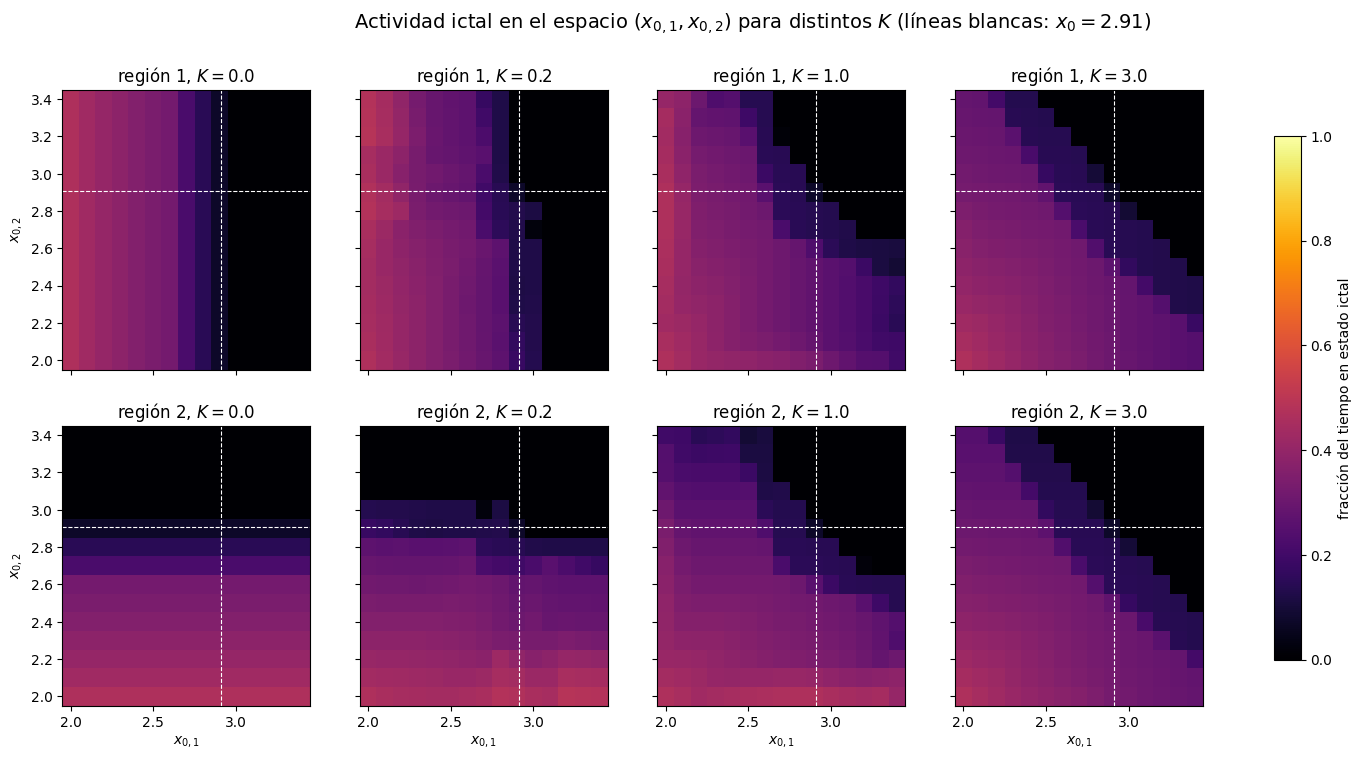

In [ ]:
def frac_ictal(x, t, t_trans, umbral=-0.5):
    m = t >= t_trans
    return np.mean(x[m] > umbral)

def mapa_calor_x0_K(K_lista, x0_vals, T=15000, dt=2.0, frac_trans=0.3, y0=None):
    n = len(x0_vals)
    A1 = np.zeros((len(K_lista), n, n)); A2 = np.zeros_like(A1)
    for k, K in enumerate(K_lista):
        for i, b in enumerate(x0_vals):
            for j, a in enumerate(x0_vals):
                t, x1, x2, _, _ = simular_N2(a, b, K, T=T, y0=y0, dt=dt)
                A1[k, i, j] = frac_ictal(x1, t, frac_trans * T)
                A2[k, i, j] = frac_ictal(x2, t, frac_trans * T)
    return A1, A2

K_mapa = [0.0, 0.2, 1.0, 3.0]
x0_mapa = np.linspace(2.0, 3.4, 15)
A1, A2 = mapa_calor_x0_K(K_mapa, x0_mapa)

fig, ax = plt.subplots(2, len(K_mapa), figsize=(4.6 * len(K_mapa), 8),
                       sharex=True, sharey=True)
for k, K in enumerate(K_mapa):
    for r, (A, nom) in enumerate([(A1, 'región 1'), (A2, 'región 2')]):
        im = ax[r, k].pcolormesh(x0_mapa, x0_mapa, A[k], shading='nearest',
                                 cmap='inferno', vmin=0, vmax=1)
        ax[r, k].axvline(2.91, color='w', ls='--', lw=0.8)
        ax[r, k].axhline(2.91, color='w', ls='--', lw=0.8)
        ax[r, k].set_title(f'{nom}, $K={K}$')
        if r == 1: ax[r, k].set_xlabel('$x_{0,1}$')
    ax[0, k].set_ylabel('$x_{0,2}$') if k == 0 else None
    ax[1, k].set_ylabel('$x_{0,2}$') if k == 0 else None
fig.colorbar(im, ax=ax, label='fracción del tiempo en estado ictal', shrink=0.85)
fig.suptitle('Actividad ictal en el espacio $(x_{0,1}, x_{0,2})$ para distintos $K$ '
             '(líneas blancas: $x_0=2.91$)', fontsize=14)
plt.show()

In [ ]:
import numpy as time

UMBRAL = -0.5
X0C    = 2.91

def _onsets_offsets(x, t, umbral=UMBRAL):
    s = x > umbral
    on  = t[:-1][~s[:-1] &  s[1:]]
    off = t[:-1][ s[:-1] & ~s[1:]]
    return on, off

def _duracion(on, off):
    d = []
    for o in on:
        f = off[off > o]
        if len(f): d.append(f[0] - o)
    return np.mean(d) if d else np.nan

def _deriva_lag(on1, on2, P):
    lags = []
    for o in on1:
        d = on2 - o
        d = d[d >= -0.5 * P]
        if len(d): lags.append(d[0])
    return np.inf if len(lags) < 2 else np.ptp(lags) / P

def _sim(x0_1, x0_2, K, T, dt, y0=None):
    if y0 is None:
        y0 = (-1.5, -1.5, x0_1, x0_2)
    sol = solve_ivp(lambda t, y: rhs_N2(t, y, x0_1, x0_2, K), (0, T), y0,
                    method='LSODA', t_eval=np.arange(0, T + dt, dt),
                    rtol=1e-6, atol=1e-8)
    return sol.t, sol.y[0], sol.y[1]

def analizar_N2(x0_1, x0_2, K, T=60000, dt=2.0, frac_trans=0.3, y0=None,
                tol_periodo=0.01, tol_deriva=0.10):
    t, x1, x2 = _sim(x0_1, x0_2, K, T, dt, y0)
    m = t >= frac_trans * T
    t, x1, x2 = t[m], x1[m], x2[m]
    on1, off1 = _onsets_offsets(x1, t)
    on2, off2 = _onsets_offsets(x2, t)
    n1, n2 = len(on1), len(on2)
    P1 = np.mean(np.diff(on1)) if n1 > 1 else np.nan
    P2 = np.mean(np.diff(on2)) if n2 > 1 else np.nan
    out = dict(n1=n1, n2=n2, P1=P1, P2=P2,
               dur1=_duracion(on1, off1), dur2=_duracion(on2, off2),
               duty2=np.mean(x2 > UMBRAL))

    if n1 == 0 and n2 == 0:
        reg = 5
    elif n2 == 0:
        reg = 4
    elif n1 == 0:
        reg = np.nan
    else:
        mismo_periodo = (np.isfinite(P1) and np.isfinite(P2)
                         and abs(P1 - P2) / P1 < tol_periodo)
        sincronizadas = mismo_periodo and _deriva_lag(on1, on2, P1) < tol_deriva
        if sincronizadas:
            reg = 2
        elif x0_2 >= X0C:
            reg = 3
        else:
            reg = 1
    out['reg'] = reg
    return out

def barrido_N2(x0_1=2.5, K_vals=None, x0_2_vals=None, **kw):
    arrs = {k: np.full((len(x0_2_vals), len(K_vals)), np.nan)
            for k in ('reg','dur1','dur2','duty2','P1','P2')}
    t0 = time.time()
    for i, b in enumerate(x0_2_vals):
        for j, K in enumerate(K_vals):
            r = analizar_N2(x0_1, b, K, **kw)
            for k in arrs: arrs[k][i, j] = r[k]
        if i % 5 == 0:
            print(f'fila {i+1}/{len(x0_2_vals)}  ({time.time()-t0:.0f}s)', flush=True)
    return arrs

In [ ]:
import time

K_vals   = np.linspace(0.0, 4.0, 41)
x02_vals = np.linspace(2.0, 4.0, 40)

res = barrido_N2(2.5, K_vals, x02_vals)

fila 1/40  (27s)
fila 6/40  (147s)
fila 11/40  (241s)
fila 16/40  (331s)
fila 21/40  (419s)
fila 26/40  (495s)
fila 31/40  (537s)
fila 36/40  (563s)


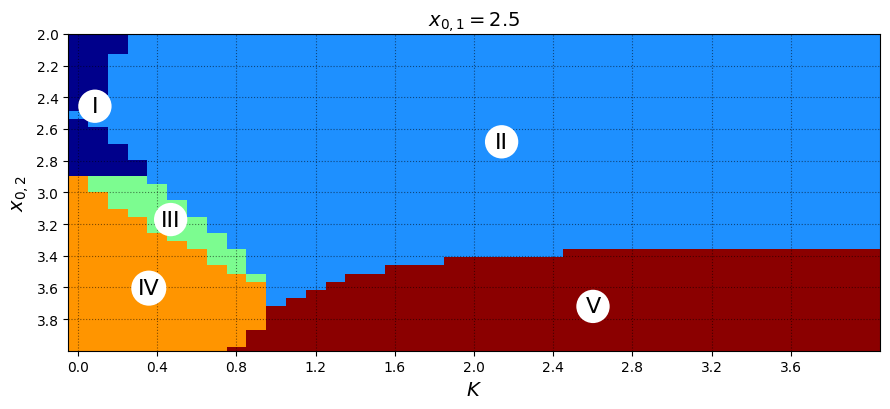

In [ ]:
from matplotlib.colors import ListedColormap

cmap_reg = ListedColormap(['#00008B', '#1E90FF', '#7CFC90', '#FF9500', '#8B0000'])
nombres  = ['I', 'II', 'III', 'IV', 'V']

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.pcolormesh(K_vals, x02_vals, res['reg'], cmap=cmap_reg,
              vmin=0.5, vmax=5.5, shading='nearest')
ax.set_ylim(x02_vals.max(), x02_vals.min())
ax.set_xticks(np.arange(0, 4.0, 0.4)); ax.set_yticks(np.arange(2.0, 4.0, 0.2))
ax.grid(ls=':', alpha=0.5, color='k')

for r, nom in enumerate(nombres, start=1):
    ii, jj = np.where(res['reg'] == r)
    if len(ii):
        ax.text(K_vals[jj].mean(), x02_vals[ii].mean(), nom, ha='center', va='center',
                fontsize=16, bbox=dict(boxstyle='circle', fc='w', ec='none'))

ax.set_xlabel('$K$', fontsize=14); ax.set_ylabel('$x_{0,2}$', fontsize=14)
ax.set_title('$x_{0,1}=2.5$', fontsize=14)
plt.tight_layout()
plt.show()

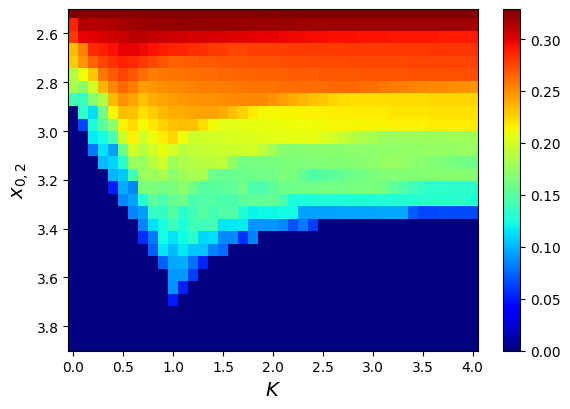

In [ ]:
vis = x02_vals >= 2.5
fig, ax = plt.subplots(figsize=(6, 4.2))
im = ax.pcolormesh(K_vals, x02_vals, res['duty2'], cmap='jet', shading='nearest',
                   vmin=0, vmax=np.nanmax(res['duty2'][vis]))
ax.set_ylim(3.9, 2.5)
ax.set_xlabel('$K$', fontsize=14); ax.set_ylabel('$x_{0,2}$', fontsize=14)
fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

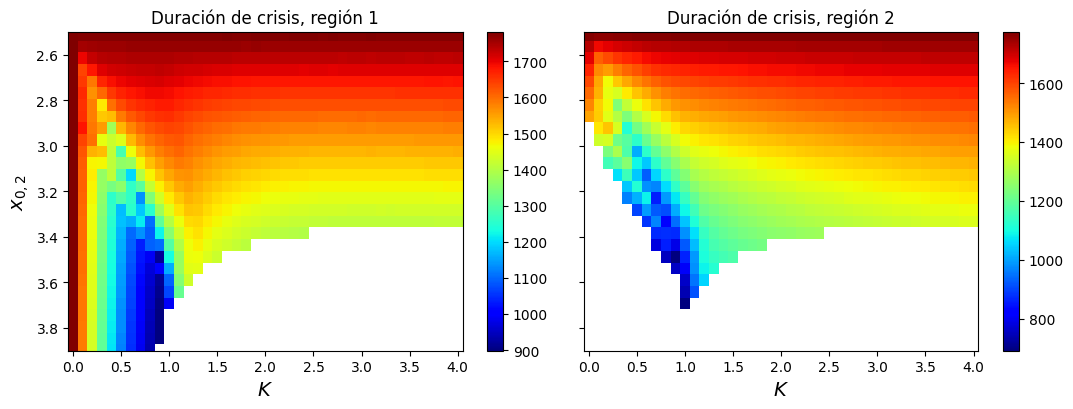

In [ ]:
ESCALA_T = 1.0
cmap_j = plt.get_cmap('jet').copy(); cmap_j.set_bad('white')
vis = x02_vals >= 2.5

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for a, clave, tit in zip(ax, ['dur1', 'dur2'], ['región 1', 'región 2']):
    datos = np.ma.masked_invalid(res[clave] * ESCALA_T)
    im = a.pcolormesh(K_vals, x02_vals, datos, cmap=cmap_j, shading='nearest',
                      vmin=np.nanmin(datos[vis]), vmax=np.nanmax(datos[vis]))
    a.set_ylim(3.9, 2.5)
    a.set_xlabel('$K$', fontsize=14); a.set_title(f'Duración de crisis, {tit}')
    fig.colorbar(im, ax=a)
ax[0].set_ylabel('$x_{0,2}$', fontsize=14)
plt.tight_layout(); plt.show()

# **Modelo con Ruido**.

In [ ]:
UMBRAL_ON, UMBRAL_OFF = -0.5, -1.0

def em_N2(x0_1, x0_2, K, sx=0.0, sz=0.0, T=50000, dt=0.1, y0=None, seed=None,
          t_trans=10000, cada=100, guardar=False):
    rng = np.random.default_rng(seed)
    x0_1, x0_2, K, sx, sz = np.broadcast_arrays(*[np.asarray(a, float) for a in (x0_1, x0_2, K, sx, sz)])
    M = x0_1.size
    x0_1, x0_2, K, sx, sz = (a.ravel() for a in (x0_1, x0_2, K, sx, sz))
    if y0 is None:
        x1 = np.full(M, -1.5); x2 = np.full(M, -1.5); z1 = x0_1.copy(); z2 = x0_2.copy()
    else:
        x1, x2, z1, z2 = (np.full(M, v, float) for v in y0)
    n = int(round(T / dt)); n_trans = int(round(t_trans / dt)); sq = np.sqrt(dt)
    ict1 = x1 > UMBRAL_ON; ict2 = x2 > UMBRAL_ON
    n1 = np.zeros(M, int); n2 = np.zeros(M, int); t_ict1 = np.zeros(M); t_ict2 = np.zeros(M)
    if guardar:
        nrec = n // cada + 1
        S = np.zeros((4, nrec, M)); S[:, 0] = (x1, x2, z1, z2)
    for k in range(1, n + 1):
        dW = rng.standard_normal((4, M))
        dx1 = (-x1**3 - 2*x1**2 + 1 - z1 + I1) * dt + sx * sq * dW[0]
        dx2 = (-x2**3 - 2*x2**2 + 1 - z2 + I1) * dt + sx * sq * dW[1]
        dz1 = (h(x1, x0_1) - z1 - K*(x2 - x1)) / tau0 * dt + sz * sq * dW[2]
        dz2 = (h(x2, x0_2) - z2 - K*(x1 - x2)) / tau0 * dt + sz * sq * dW[3]
        x1 += dx1; x2 += dx2; z1 += dz1; z2 += dz2
        on1 = ~ict1 & (x1 > UMBRAL_ON); on2 = ~ict2 & (x2 > UMBRAL_ON)
        ict1 = np.where(x1 > UMBRAL_ON, True, np.where(x1 < UMBRAL_OFF, False, ict1))
        ict2 = np.where(x2 > UMBRAL_ON, True, np.where(x2 < UMBRAL_OFF, False, ict2))
        if k > n_trans:
            n1 += on1; n2 += on2; t_ict1 += ict1 * dt; t_ict2 += ict2 * dt
        if guardar and k % cada == 0:
            S[:, k // cada] = (x1, x2, z1, z2)
    out = dict(n1=n1, n2=n2, duty1=t_ict1/(T - t_trans), duty2=t_ict2/(T - t_trans))
    if guardar:
        out['t'] = np.arange(nrec) * cada * dt
        out['x1'], out['x2'], out['z1'], out['z2'] = S
    return out


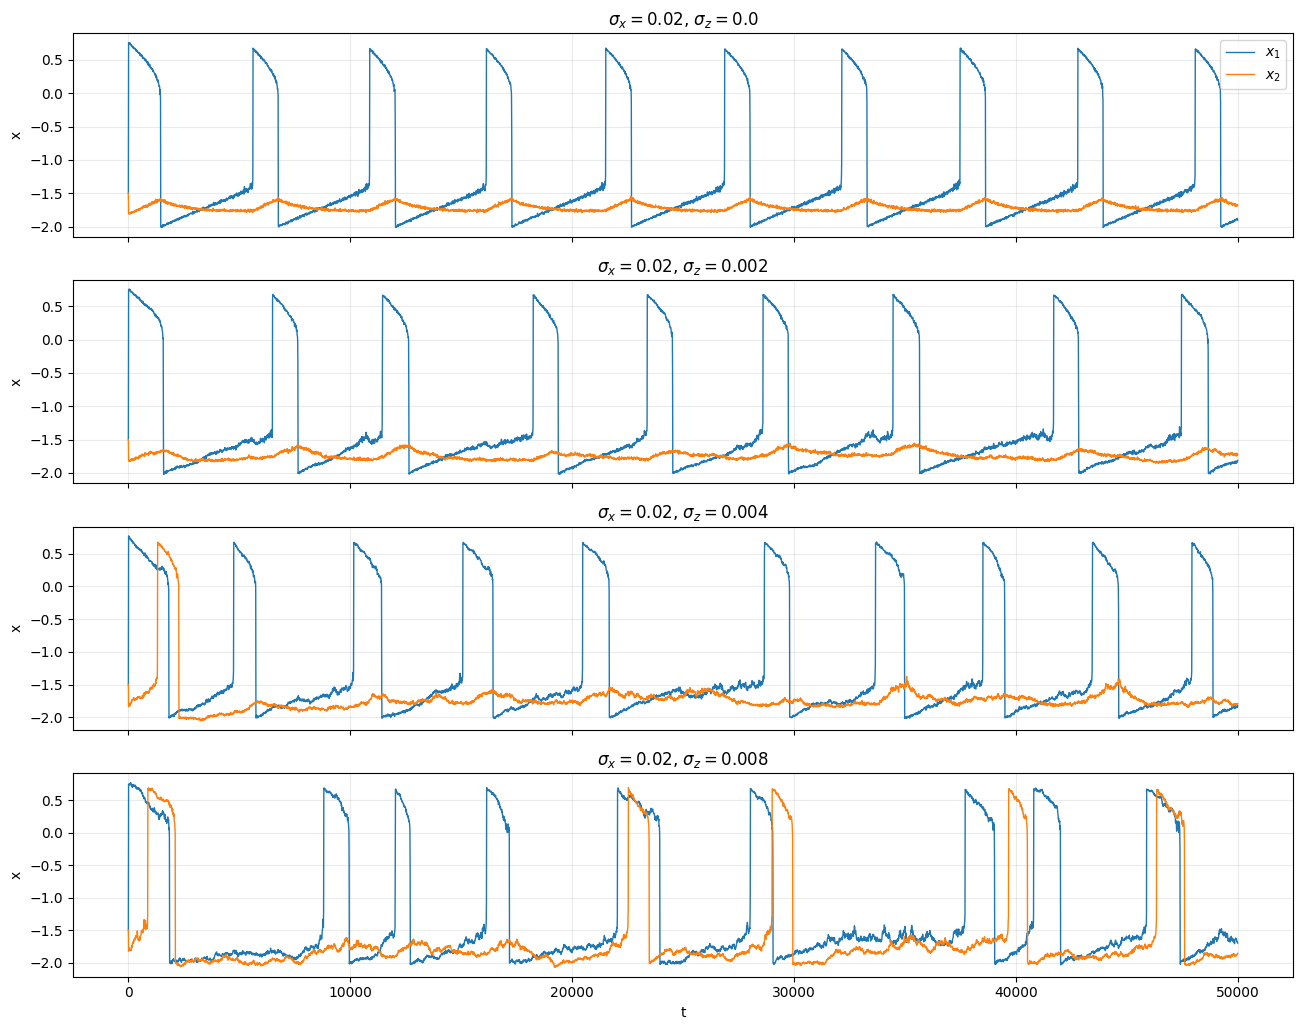

In [ ]:
SX = 0.02
sz_lista = np.array([0.0, 0.002, 0.004, 0.008])

ser = em_N2(2.5, 3.5, 0.5, SX, sz_lista, T=50000, dt=0.1, seed=11,
            t_trans=0, guardar=True)

fig, ax = plt.subplots(len(sz_lista), 1, figsize=(13, 2.6 * len(sz_lista)), sharex=True)
for m, sz in enumerate(sz_lista):
    ax[m].plot(ser['t'], ser['x1'][:, m], lw=1.0, label='$x_1$')
    ax[m].plot(ser['t'], ser['x2'][:, m], lw=1.0, label='$x_2$')
    ax[m].set_ylabel('x'); ax[m].grid(alpha=0.25)
    ax[m].set_title(rf'$\sigma_x={SX}$, $\sigma_z={sz}$')
ax[0].legend(loc='upper right'); ax[-1].set_xlabel('t')
plt.tight_layout()
plt.show()

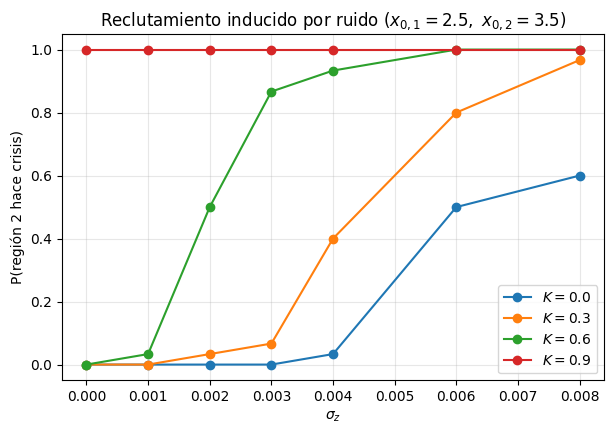

In [ ]:
R = 30
sz_vals = np.array([0.0, 0.001, 0.002, 0.003, 0.004, 0.006, 0.008])
K_curvas = [0.0, 0.3, 0.6, 0.9]

SZ, KK = np.meshgrid(sz_vals, K_curvas)
SZr = np.repeat(SZ.ravel(), R); KKr = np.repeat(KK.ravel(), R)

r = em_N2(2.5, 3.5, KKr, SX, SZr, T=50000, dt=0.1, seed=21)
P_rec = (r['n2'] > 0).reshape(len(K_curvas), len(sz_vals), R).mean(axis=2)

plt.figure(figsize=(7, 4.5))
for i, K in enumerate(K_curvas):
    plt.plot(sz_vals, P_rec[i], 'o-', label=f'$K={K}$')
plt.xlabel(r'$\sigma_z$'); plt.ylabel('P(región 2 hace crisis)')
plt.title(r'Reclutamiento inducido por ruido ($x_{0,1}=2.5,\ x_{0,2}=3.5$)')
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [ ]:
import os, time
os.makedirs('figuras', exist_ok=True)

# --- reemplaza la celda 14 ---
def cond_iniciales(N, rng):
    x_ini = 4.0 * (rng.random(N) - 0.5)          # U[-2, 2]
    z_ini = 3.0 + 2.0 * (rng.random(N) - 0.5)    # U[2, 4]
    return x_ini, z_ini

def matriz_W(N, K):
    """Todos con todos, peso K entre cada par."""
    return K * (np.ones((N, N)) - np.eye(N))

def rhs_N(t, y, K, x0_list, W=None):
    """y = [x_1..x_N, z_1..z_N].  dz_i = (h(x_i) - z_i - sum_j W_ij (x_j - x_i)) / tau0"""
    N = len(x0_list)
    if W is None:
        W = matriz_W(N, K)
    x, z = y[:N], y[N:]
    acople = W @ x - W.sum(1) * x
    dx = -x**3 - 2*x**2 + 1 - z + I1
    dz = (h(x, x0_list) - z - acople) / tau0
    return np.concatenate([dx, dz])

def jac_N(t, y, K, x0_list, W=None):
    """Jacobiano analítico (acelera mucho LSODA para N grande)."""
    N = len(x0_list)
    if W is None:
        W = matriz_W(N, K)
    x = y[:N]; idx = np.arange(N)
    J = np.zeros((2*N, 2*N))
    J[idx, idx] = -3*x**2 - 4*x
    J[idx, N + idx] = -1.0
    J[N:, :N] = (np.diag(dh_dx(x) + W.sum(1)) - W) / tau0
    J[N + idx, N + idx] = -1.0 / tau0
    return J

def ics_N(N, modo='aleatoria', eps=1e-2, base=(-1.2, 3.0), seed=42):
    """'aleatoria': U[-2,2] x U[2,4].  'casi_sync': mismo estado + perturbación eps."""
    rng = np.random.default_rng(seed)
    if modo == 'aleatoria':
        x, z = cond_iniciales(N, rng)
    else:
        x = base[0] + eps * rng.standard_normal(N)
        z = base[1] + eps * rng.standard_normal(N)
    return np.concatenate([x, z])

def simular_N(x0_list, K=None, W=None, T=30000, y0=None, dt=1.0, seed=42,
              rtol=1e-6, atol=1e-8):
    x0_list = np.asarray(x0_list, float); N = len(x0_list)
    if W is None:
        W = matriz_W(N, K)
    if y0 is None:
        y0 = ics_N(N, 'aleatoria', seed=seed)
    sol = solve_ivp(lambda t, y: rhs_N(t, y, None, x0_list, W), (0, T), y0,
                    method='LSODA', jac=lambda t, y: jac_N(t, y, None, x0_list, W),
                    t_eval=np.arange(0, T + dt, dt), rtol=rtol, atol=atol)
    return sol.t, sol.y[:N], sol.y[N:]

def campo_medio(x):                 # x: (N, nt)
    return x.mean(axis=0)

def sigma_perp2_t(x):               # σ⊥²(t) = var_i(x_i - x̄) en cada instante
    return ((x - x.mean(axis=0))**2).mean(axis=0)

casi_sync  sx0=0.0 K·N=1.0: listo (11s el último N)
aleatoria  sx0=0.0 K·N=1.0: listo (39s el último N)
aleatoria  sx0=0.0 K·N=5.0: listo (8s el último N)
aleatoria  sx0=0.1 K·N=5.0: listo (15s el último N)


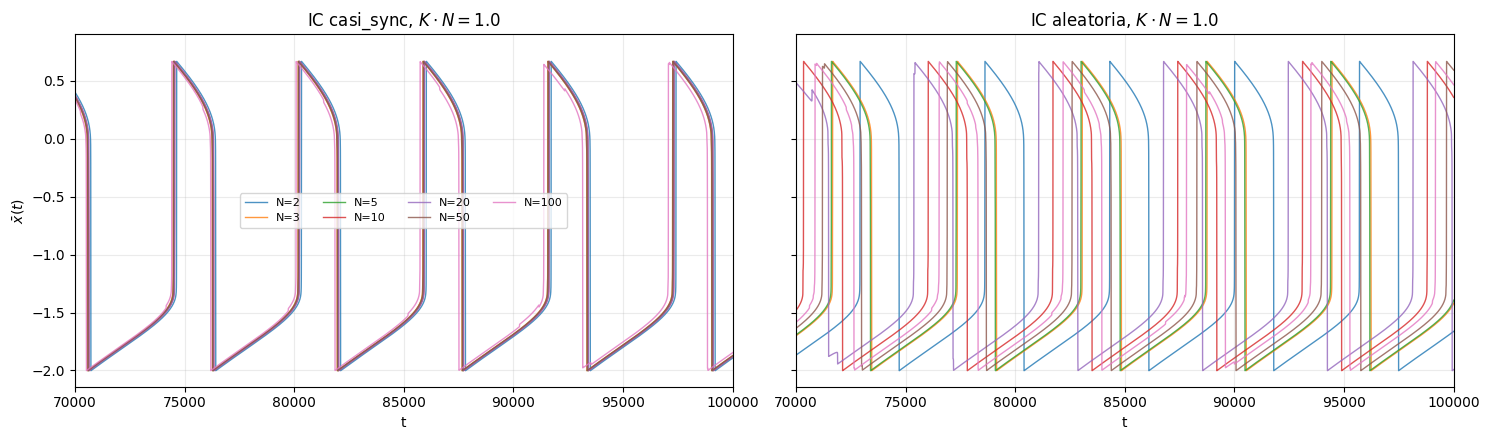

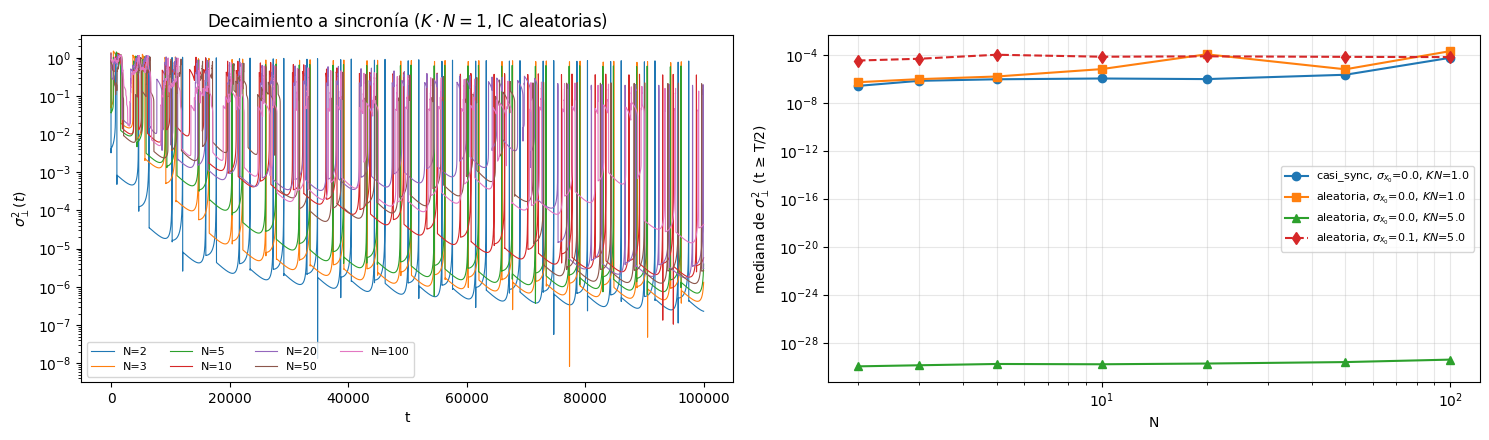

In [ ]:
N_lista = [2, 3, 5, 10, 20, 50, 100]
T, dt = 100000, 2.0

def correr_hom(N, KN, modo='aleatoria', x0m=2.5, sx0=0.0, T=30000, dt=1.0, seed=42):
    rng = np.random.default_rng(seed)
    x0_list = x0m + sx0 * rng.standard_normal(N)       # sx0=0 -> regiones idénticas
    return simular_N(x0_list, K=KN / N, T=T, y0=ics_N(N, modo, seed=seed), dt=dt)

# (modo de IC, dispersión de x0, K·N)
configs = [('casi_sync', 0.0, 1.0), ('aleatoria', 0.0, 1.0),
           ('aleatoria', 0.0, 5.0), ('aleatoria', 0.1, 5.0)]
res = {}
for modo, sx0, KN in configs:
    for N in N_lista:
        t0 = time.time()
        res[(modo, sx0, KN, N)] = correr_hom(N, KN, modo, sx0=sx0, T=T, dt=dt)
    print(f'{modo:10s} sx0={sx0} K·N={KN}: listo ({time.time()-t0:.0f}s el último N)')

# --- Figura: campo medio ---
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for a, cfg in zip(ax, [('casi_sync', 0.0, 1.0), ('aleatoria', 0.0, 1.0)]):
    for N in N_lista:
        t, x, z = res[cfg + (N,)]
        a.plot(t, campo_medio(x), lw=1.0, alpha=0.8, label=f'N={N}')
    a.set_title(f'IC {cfg[0]}, $K\\cdot N={cfg[2]}$'); a.set_xlabel('t'); a.grid(alpha=0.25)
    a.set_xlim(T - 30000, T)
ax[0].set_ylabel(r'$\bar x(t)$'); ax[0].legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.savefig('figuras/Ninf_campomedio.png', dpi=150); plt.show()

# --- Figura: σ⊥²(t) y σ⊥² vs N ---
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for N in N_lista:
    t, x, z = res[('aleatoria', 0.0, 1.0, N)]
    ax[0].semilogy(t, sigma_perp2_t(x) + 1e-30, lw=0.8, label=f'N={N}')
ax[0].set_xlabel('t'); ax[0].set_ylabel(r'$\sigma_\perp^2(t)$'); ax[0].legend(ncol=4, fontsize=8)
ax[0].set_title(r'Decaimiento a sincronía ($K\cdot N=1$, IC aleatorias)')
for cfg, estilo in zip(configs, ['o-', 's-', '^-', 'd--']):
    s = [np.median(sigma_perp2_t(res[cfg + (N,)][1])[res[cfg + (N,)][0] >= T/2]) for N in N_lista]
    ax[1].loglog(N_lista, np.array(s) + 1e-30, estilo,
                 label=f'{cfg[0]}, $\\sigma_{{x_0}}$={cfg[1]}, $KN$={cfg[2]}')
ax[1].set_xlabel('N'); ax[1].set_ylabel(r'mediana de $\sigma_\perp^2$ (t ≥ T/2)')
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

In [ ]:
def jac_perp(x_s, KN):
    a = -3*x_s**2 - 4*x_s
    return np.array([[a, -1.0], [(dh_dx(x_s) + KN) / tau0, -1.0 / tau0]])

KN_lista = [0.0, 0.25, 0.5, 1.0, 2.0, 5.0]
for a in [3.5, 2.5]:
    print(f'\n=== x0 = {a} ===')
    for xs_ in puntos_fijos(a):
        lam_long = np.linalg.eigvals(jacobiano(xs_))
        print(f'punto fijo x* = {xs_:.4f} | modo longitudinal: max Re = {lam_long.real.max():+.5f}')
        for KN_ in KN_lista:
            lam_p = np.linalg.eigvals(jac_perp(xs_, KN_))
            est = 'estable' if lam_p.real.max() < 0 else 'inestable'
            print(f'   K·N = {KN_:4.2f} | autovalores transversales = {np.round(lam_p, 5)} -> {est}')

# Verificación: Jacobiano completo 2N x 2N vs. teoría (debe coincidir para todo N con K·N fijo)
def verificar_jacobiano_completo(x0_val, KN_, N):
    xs_ = puntos_fijos(x0_val)[0]; zs_ = h(xs_, x0_val)
    y = np.concatenate([np.full(N, xs_), np.full(N, zs_)])
    J = jac_N(0, y, None, np.full(N, x0_val), matriz_W(N, KN_ / N))
    num = np.linalg.eigvals(J).real.max()
    teo = max(np.linalg.eigvals(jacobiano(xs_)).real.max(),
              np.linalg.eigvals(jac_perp(xs_, KN_)).real.max())
    return num, teo

for N in [2, 5, 10, 50]:
    num, teo = verificar_jacobiano_completo(3.5, 1.0, N)
    print(f'N={N:3d}: max Re λ completo = {num:+.8f} | teoría = {teo:+.8f} | dif = {abs(num-teo):.1e}')


=== x0 = 3.5 ===
punto fijo x* = -1.8186 | modo longitudinal: max Re = -0.00035
   K·N = 0.00 | autovalores transversales = [-2.64739e+00 -3.50000e-04] -> estable
   K·N = 0.25 | autovalores transversales = [-2.64736e+00 -3.80000e-04] -> estable
   K·N = 0.50 | autovalores transversales = [-2.64732e+00 -4.20000e-04] -> estable
   K·N = 1.00 | autovalores transversales = [-2.64726e+00 -4.80000e-04] -> estable
   K·N = 2.00 | autovalores transversales = [-2.64713e+00 -6.10000e-04] -> estable
   K·N = 5.00 | autovalores transversales = [-2.64673e+00 -1.01000e-03] -> estable

=== x0 = 2.5 ===
punto fijo x* = -0.5450 | modo longitudinal: max Re = +1.28702
   K·N = 0.00 | autovalores transversales = [1.28702 0.00159] -> inestable
   K·N = 0.25 | autovalores transversales = [1.28695 0.00166] -> inestable
   K·N = 0.50 | autovalores transversales = [1.28688 0.00173] -> inestable
   K·N = 1.00 | autovalores transversales = [1.28675 0.00186] -> inestable
   K·N = 2.00 | autovalores transversale

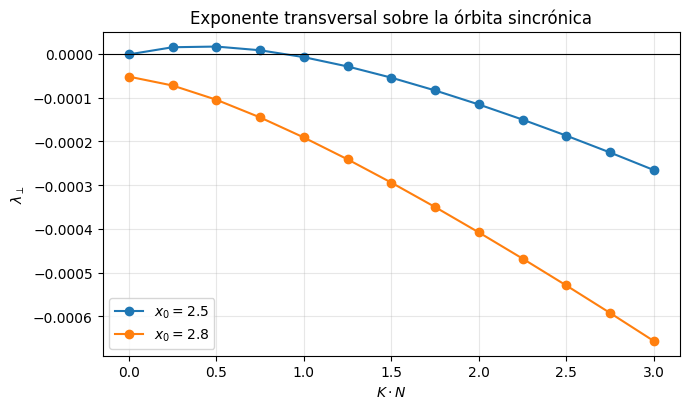

In [ ]:
def lyap_perp(x0_val, KN, T=60000, t_trans=20000, paso=100.0):
    """λ⊥ de la ecuación variacional sobre la órbita sincrónica (renormalización por tramos)."""
    def rhs(t, u):
        x, z, dx_, dz_ = u
        a = -3*x**2 - 4*x
        return [-x**3 - 2*x**2 + 1 - z + I1,
                (h(x, x0_val) - z) / tau0,
                a*dx_ - dz_,
                ((dh_dx(x) + KN)*dx_ - dz_) / tau0]
    u = np.array([-1.2, 3.0, 1.0, 0.0]); t = 0.0; acum = 0.0
    while t < T - 1e-9:
        sol = solve_ivp(rhs, (t, t + paso), u, method='LSODA', rtol=1e-8, atol=1e-10)
        u = sol.y[:, -1].copy(); nrm = np.hypot(u[2], u[3]); u[2:] /= nrm
        if t >= t_trans:
            acum += np.log(nrm)
        t += paso
    return acum / (T - t_trans)

KN_grid = np.linspace(0, 3, 13)
lyap = {a: np.array([lyap_perp(a, k) for k in KN_grid]) for a in [2.5, 2.8]}   # ~25 s

fig, ax = plt.subplots(figsize=(7, 4.2))
for a_, lam in lyap.items():
    ax.plot(KN_grid, lam, 'o-', label=f'$x_0={a_}$')
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('$K\\cdot N$'); ax.set_ylabel(r'$\lambda_\perp$')
ax.set_title('Exponente transversal sobre la órbita sincrónica'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

N=2: 30s
N=4: 33s
N=10: 45s
N=50: 80s


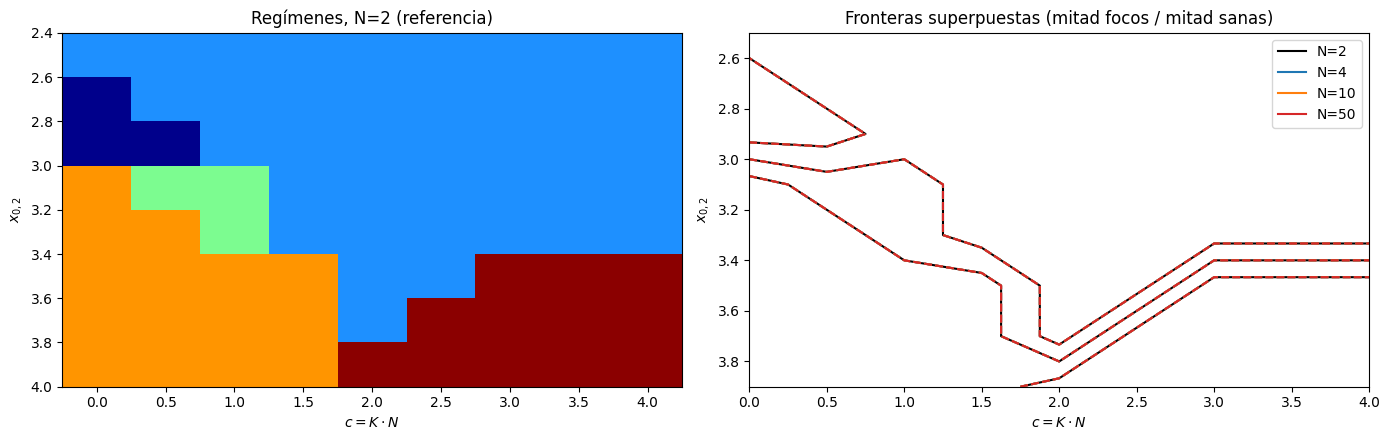

In [ ]:
def ics_pob(N, n_foco, x0_1, x0_2, eps=1e-2, seed=0):
    rng = np.random.default_rng(seed)
    x0_list = np.r_[np.full(n_foco, x0_1), np.full(N - n_foco, x0_2)]
    x = -1.5 + eps * rng.standard_normal(N)       # reposo + perturbación pequeña
    z = x0_list + eps * rng.standard_normal(N)
    return x0_list, np.concatenate([x, z])

def clasificar(t, xa, xb, x0_b, frac_trans=0.3, tol_periodo=0.01, tol_deriva=0.10):
    """Misma lógica que analizar_N2, sobre las medias de cada población."""
    m = t >= frac_trans * t[-1]
    t, xa, xb = t[m], xa[m], xb[m]
    on1, _ = _onsets_offsets(xa, t); on2, _ = _onsets_offsets(xb, t)
    n1, n2 = len(on1), len(on2)
    P1 = np.mean(np.diff(on1)) if n1 > 1 else np.nan
    P2 = np.mean(np.diff(on2)) if n2 > 1 else np.nan
    if n1 == 0 and n2 == 0: return 5
    if n2 == 0:             return 4
    if n1 == 0:             return np.nan
    mismo = np.isfinite(P1) and np.isfinite(P2) and abs(P1 - P2) / P1 < tol_periodo
    if mismo and _deriva_lag(on1, on2, P1) < tol_deriva: return 2
    return 3 if x0_b >= X0C else 1

def mapa_regimenes_N(N, n_foco, c_vals, x02_vals, x0_1=2.5, T=40000, dt=2.0, eps=1e-2):
    reg = np.full((len(x02_vals), len(c_vals)), np.nan); sig = np.full_like(reg, np.nan)
    for i, b in enumerate(x02_vals):
        x0_list, y0 = ics_pob(N, n_foco, x0_1, b, eps=eps)
        for j, c in enumerate(c_vals):
            t, x, z = simular_N(x0_list, K=c / N, T=T, y0=y0, dt=dt)
            reg[i, j] = clasificar(t, x[:n_foco].mean(0), x[n_foco:].mean(0), b)
            m = t >= 0.3 * T                       # dispersión intra-población
            dev = np.r_[x[:n_foco][:, m] - x[:n_foco][:, m].mean(0),
                        x[n_foco:][:, m] - x[n_foco:][:, m].mean(0)]
            sig[i, j] = np.mean(dev**2)
    return reg, sig

c_vals   = np.linspace(0.0, 4.0, 9)
x02_vals = np.linspace(2.5, 3.9, 8)
maps = {}
for N in [2, 4, 10, 50]:
    t0 = time.time()
    maps[N] = mapa_regimenes_N(N, N // 2, c_vals, x02_vals)
    print(f'N={N}: {time.time()-t0:.0f}s')          # ~15-45 s por N

from matplotlib.colors import ListedColormap
cmap_reg = ListedColormap(['#00008B', '#1E90FF', '#7CFC90', '#FF9500', '#8B0000'])
cols = {2: 'k', 4: 'C0', 10: 'C1', 50: 'C3'}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].pcolormesh(c_vals, x02_vals, maps[2][0], cmap=cmap_reg, vmin=0.5, vmax=5.5, shading='nearest')
ax[0].set_title('Regímenes, N=2 (referencia)')
for N, col in cols.items():
    ax[1].contour(c_vals, x02_vals, np.ma.masked_invalid(maps[N][0]),
                  levels=[1.5, 2.5, 3.5, 4.5], colors=col, linewidths=1.5,
                  linestyles='-' if N == 2 else '--')
    ax[1].plot([], [], color=col, label=f'N={N}')
ax[1].legend(); ax[1].set_title('Fronteras superpuestas (mitad focos / mitad sanas)')
for a in ax:
    a.set_xlabel('$c=K\\cdot N$'); a.set_ylabel('$x_{0,2}$'); a.invert_yaxis()
plt.tight_layout(); plt.savefig('figuras/Ninf_fronteras.png', dpi=150); plt.show()

In [ ]:
ref = np.nan_to_num(maps[2][0], nan=-1)
for N in [4, 10, 50]:
    disc = np.mean(np.nan_to_num(maps[N][0], nan=-1) != ref)
    print(f'N={N:3d}: celdas con régimen distinto a N=2: {100*disc:.1f}% | '
          f'max dispersión intra-población = {np.nanmax(maps[N][1]):.1e}')

N=  4: celdas con régimen distinto a N=2: 0.0% | max dispersión intra-población = 3.2e-03
N= 10: celdas con régimen distinto a N=2: 0.0% | max dispersión intra-población = 4.3e-03
N= 50: celdas con régimen distinto a N=2: 0.0% | max dispersión intra-población = 2.3e-02


In [ ]:
r2, _  = mapa_regimenes_N(2, 1, c_vals, x02_vals)
r10, _ = mapa_regimenes_N(10, 1, c_vals, x02_vals)
print('discrepancia N=10 (1 foco) vs N=2:',
      np.mean(np.nan_to_num(r10, nan=-1) != np.nan_to_num(r2, nan=-1)))

discrepancia N=10 (1 foco) vs N=2: 0.4166666666666667
